# Multi-section integration with HEBI

Three serial sections of the mouse central nervous system, profiled with
STARmap PLUS, encoded together by one model.

The point of doing this jointly rather than one section at a time is that
HEBI's upper-level prototypes are shared. Every cell in every section
attends to the same set of niche prototypes, so a niche label means the
same thing in section 1 as in section 3. No batch correction step is
applied, and none is needed: the sections are never aligned to each
other, they are simply read by the same model.

The work is split into three stages, because they cost very different
amounts:

| stage | what it does | cost |
| --- | --- | --- |
| **encode** | adapt the model, run it over every cell | minutes to hours |
| **cluster** | group the resulting representations | seconds |
| **GRN** | what the learned gene attention says | minutes |

Keeping them separate means trying a different number of clusters does
not re-encode anything.

**Runtime.** Roughly 30–60 minutes on a single GPU for the whole
notebook. Preprocessing three sections takes about 10 minutes, most of it
METIS partitioning; encoding with 10 epochs of adaptation takes about 15.

## 1. Setup

Edit these four paths. Everything else follows from them.

In [1]:
from pathlib import Path

# --- edit these -------------------------------------------------------
DATA_DIR   = Path("/DATA1/Roxana/Data")
VOCAB_PATH = Path("/DATA1/Roxana/Hierarchy/Two_levels/default_gene_vocab.json")
CHECKPOINT = Path("/DATA1/Roxana/hebi_repo/notebooks/hebi_hybrid_oldL0.pt")
#CHECKPOINT = Path("/DATA1/Roxana/hebi_repo/notebooks/starmap_tutorial/results/hebi_continual.pt")
WORK_DIR   = Path("./starmap_tutorial_n")
WORK_DIR2   = Path("./starmap_tutorial")
# ----------------------------------------------------------------------
SECTION_NAMES = ["medial", "intermediate", "lateral"]
# The three sections, ordered medial to lateral. This order is the order
# every downstream list follows, and it is what the labels attach to.
SECTIONS = [
    ("medial",       "starmap_plus_mouse_cns_section_1"),
    ("intermediate", "starmap_plus_mouse_cns_section_2"),
    ("lateral",      "starmap_plus_mouse_cns_section_3"),
]

H5AD_FILES = [DATA_DIR / f"{stem}.h5ad" for _, stem in SECTIONS]
LABELS     = [label for label, _ in SECTIONS]

PROCESSED_DIR = WORK_DIR / "processed"
PROCESSED_DIR2 = WORK_DIR2 / "processed"
RESULTS_DIR   = WORK_DIR / "results"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

ANNOTATION = "Main_molecular_tissue_region"   # used only for scoring

for path in H5AD_FILES:
    print(f"{'found  ' if path.exists() else 'MISSING'} {path.name}")

found   starmap_plus_mouse_cns_section_1.h5ad
found   starmap_plus_mouse_cns_section_2.h5ad
found   starmap_plus_mouse_cns_section_3.h5ad


## 2. What is in the data

HEBI needs two things from an `.h5ad`: an expression matrix, and spatial
coordinates in `obsm`. Annotations are optional and are used here only to
score the result, never to produce it.

In [2]:
import scanpy as sc

adata = sc.read_h5ad(H5AD_FILES[0])
print(adata)
print()
print("spatial coordinates:", [k for k in adata.obsm])
print("layers:            ", [k for k in adata.layers])
print("annotated regions: ", adata.obs[ANNOTATION].nunique())
del adata

AnnData object with n_obs × n_vars = 207591 × 1022
    obs: 'organ', 'biosample_id', 'disease__ontology_label', 'Z', 'Main_molecular_tissue_region', 'species__ontology_label', 'library_preparation_protocol__ontology_label', 'sex', 'library_preparation_protocol', 'Molecular_spatial_cell_type', 'AAV_PHP_eB_circular_RNA_barcode_count', 'Main_molecular_cell_type', 'donor_id', 'Sub_molecular_cell_type', 'Sub_molecular_tissue_region', 'organ__ontology_label', 'disease', 'species', 'label'
    obsm: 'spatial'
    layers: 'raw'

spatial coordinates: ['spatial']
layers:             ['raw']
annotated regions:  16


The three sections are serial slices through one brain, so they share
anatomy but differ in which structures are present — some regions appear
in one section and not another. That is the situation joint encoding is
meant to handle.

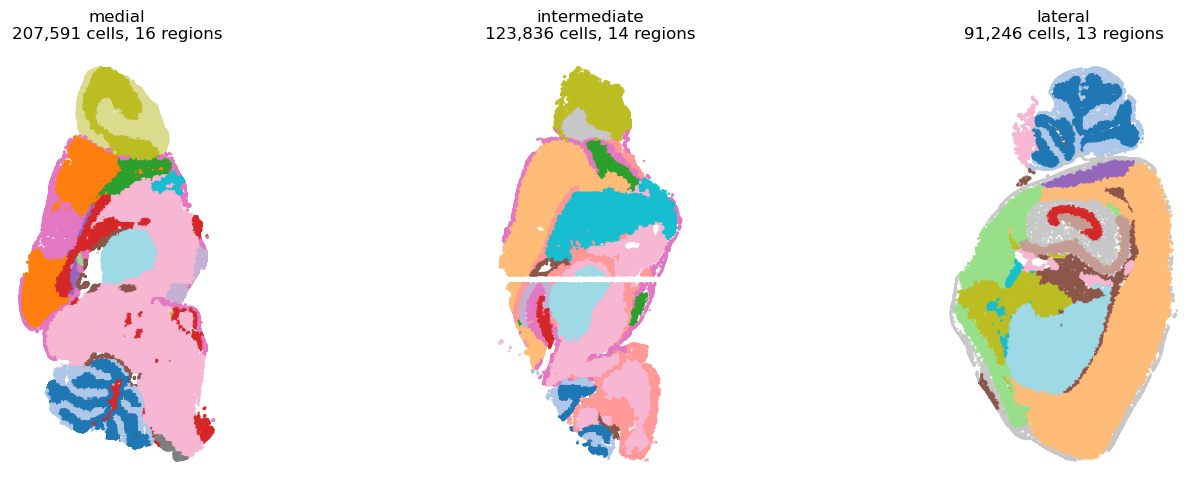

In [3]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, label, path in zip(axes, LABELS, H5AD_FILES):
    a = sc.read_h5ad(path)
    coords = np.asarray(a.obsm["spatial"])[:, :2]
    regions = a.obs[ANNOTATION].astype(str)
    ax.scatter(coords[:, 0], coords[:, 1],
               c=regions.astype("category").cat.codes,
               cmap="tab20", s=1, alpha=0.7, rasterized=True)
    ax.set_title(f"{label}\n{a.n_obs:,} cells, {regions.nunique()} regions")
    ax.set_aspect("equal")
    ax.axis("off")
    del a
plt.tight_layout()
plt.show()

## 3. Choosing the graph neighbourhood

Each cell is connected to its `k` nearest spatial neighbours, and `k`
controls how much of the surroundings enters that cell's representation.

`k` is a count, but what matters is the physical distance it covers, and
that depends on how densely the tissue is sampled. The same `k` spans a
very different area on a dense section than on a sparse one. So rather
than copying a number, measure the reach first.

The reach is the distance to the k-th neighbour expressed in cell
diameters, where one diameter is roughly the spacing between touching
cells. It is computed from coordinates alone — no annotations — so `k` is
never selected against the labels the result will later be scored
against.

In [4]:
from hebi.data.graph_diagnostics import (
    neighbour_diagnostics, suggest_k, report, _find_spatial
)

adata = sc.read_h5ad(H5AD_FILES[0])
rows, scale = neighbour_diagnostics(_find_spatial(adata), n_sample=20000)
report(rows, scale, suggest_k(rows), name=LABELS[0])
del adata

  207,591 cells; querying 20,000 of them up to k=100

  median nearest-neighbour distance: 41.265
  implied cell diameter:             82.531

      k       reach   diameters
  -----------------------------
      3       71.34        0.86
      5       96.27        1.17
     10      143.85        1.74
     15      181.12        2.19
     20      212.39        2.57
     30      264.74        3.21
     40      308.88        3.74
     50      348.50        4.22
     75      432.69        5.24
    100      503.89        6.11

  suggested k: 15 to 20   (2.19 to 2.57 cell diameters)
  target is 2.0 to 3.0 diameters: a cell plus its first two rings of contacts.

  For reference, the sections HEBI was developed on:
    platform   tissue            NN dist    k   reach
    Xenium     human breast         9.54   30    2.05
    MERSCOPE   human breast         7.71   30    2.28
    CosMx      human liver           n/a   30    2.42
    STARmap    mouse CNS           41.27   30    3.21
  This is a s

Two to three cell diameters covers a cell and its first two rings of
contacts, which is a reasonable starting range.

`k=30` is used here. At `k=5` the neighbourhood spans barely one cell
diameter and the resulting domains come out visibly speckled; at `k=30`
they are contiguous and follow recognisable anatomy.

In [5]:
K_NEIGHBORS = 40

## 4. Preprocessing

Each `.h5ad` becomes a `.pt` section holding the expression matrix on the
shared gene vocabulary, the spatial graph, the METIS partition, and
metadata describing how it was built.

Two things happen here worth knowing about.

**Gene harmonisation.** Every section is projected onto one fixed
vocabulary, so sections with different panels end up in a common feature
space. Mouse symbols are mapped to their human counterparts, and genes
outside the vocabulary are dropped. The coverage is printed.

**Normalisation is detected, not assumed.** Applying `log1p` to data that
has already been logged produces values that look plausible and are
wrong, and nothing downstream can detect it. So the state of the matrix
is reported and `log1p` is applied only when missing. Library-size
normalisation is a separate, explicit choice.

In [6]:
from hebi.data.preprocess import preprocess_h5ad

# Preprocessing is the slow part — mostly METIS — so it is skipped when
# the output already exists. Set this True after changing k, the counts
# layer, or normalisation.
OVERWRITE = False

section_files = []
for path in H5AD_FILES:
    written = preprocess_h5ad(
        h5ad_path=path,
        out_root=PROCESSED_DIR,
        vocab_path=VOCAB_PATH,
        task="clustering",
        k=K_NEIGHBORS,
        species="Mouse",
        counts_layer="raw",   # these files keep raw counts in layers["raw"]
        overwrite=OVERWRITE,
    )
    section_files.extend(p.name for p in written)

print("\nsections ready:")
for name in section_files:
    print(" ", name)

/home/tower4/miniconda3/envs/hebi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



starmap_plus_mouse_cns_section_1.h5ad: already processed, reusing starmap_plus_mouse_cns_section_1.pt

starmap_plus_mouse_cns_section_2.h5ad: already processed, reusing starmap_plus_mouse_cns_section_2.pt

starmap_plus_mouse_cns_section_3.h5ad: already processed, reusing starmap_plus_mouse_cns_section_3.pt

sections ready:
  starmap_plus_mouse_cns_section_1.pt
  starmap_plus_mouse_cns_section_2.pt
  starmap_plus_mouse_cns_section_3.pt


Each `.pt` records how it was built. Read this back before reusing
sections from an earlier run: `k_neighbors` and `normalisation_state`
decide whether they are comparable with anything else you have, and
`reach_cell_diameters` says what that `k` meant physically for this
tissue.

In [7]:
import torch

meta = torch.load(PROCESSED_DIR / section_files[0],
                  map_location="cpu", weights_only=False)["meta"]
for key, value in meta.items():
    print(f"  {key:<28} {value}")

  species                      Mouse
  tissue                       N/A
  disease                      Normal
  normalisation_on_input       raw_counts
  normalisation_applied        ['log1p']
  normalisation_state          log_transformed
  k_neighbors                  40
  n_metis_clusters             1024
  seed                         42
  reach_cell_diameters         3.74


## 5. Stage one: encoding

This is the expensive stage and the only one that touches the model.

**Mode.** `zero_shot` encodes with frozen weights. `continual` first
adapts for a few epochs on these sections, using exactly the
self-supervised objective from pretraining, then encodes. The two share
the same encoding procedure; they differ only in whether a short
adaptation precedes it.

**Initialisation.** `pretrained` loads the foundation weights. `random`
starts from scratch — the baseline that shares the architecture but not
the pretrained knowledge. `hybrid` randomises only the cell-level
encoder. This run uses `random`, matching the published STARmap setting.

**What comes out.** Three representations per cell, written into
`adata.obsm` as `z0`, `z1`, `z2`, plus the prototype assignment in
`adata.obs["prototypes"]`. That last one is not a clustering: it is the
Level-2 attention argmax, read straight from the forward pass.

`grn=True` also builds the gene-interaction graph and trains the
refinement layer during adaptation, which stage three needs. It requires
`mode="continual"` — in zero-shot the layer is never trained, so its
attention would carry no signal.

In [8]:
from hebi.inference.pipeline import encode_sections

sections, ctx = encode_sections(
    checkpoint_path=str(CHECKPOINT),
    data_dir=str(PROCESSED_DIR),
    section_files=section_files,
    h5ad_files=[str(p) for p in H5AD_FILES],
    vocab_path=str(VOCAB_PATH),
    section_labels=LABELS,

    mode="continual",
    init="random",
    num_epochs=15,
    lr=1e-4,

    grn=False,
    per_section_grn=True, 
    species="Mouse",

    output_dir=str(RESULTS_DIR),
    seed=2025,
)

Seed set to 2025
Loading /DATA1/Roxana/Data/starmap_plus_mouse_cns_section_1.h5ad


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed


  homolog mapping: 962/1022 genes mapped to human symbols


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed


Covered genes: 993/1022 (97.16%)
  207591 cells, 993 genes
Loading /DATA1/Roxana/Data/starmap_plus_mouse_cns_section_2.h5ad


Input sequence provided is already in string format. No operation performed
Input sequence provided is already in string format. No operation performed


... (7 outputs left out)

Encoding starmap_tutorial_n/processed/starmap_plus_mouse_cns_section_2.pt: 100%|


📦 Loading preprocessed slide from starmap_tutorial_n/processed/starmap_plus_mouse_cns_section_3.pt
✅ Loaded data: X=torch.Size([91246, 993]), coords=torch.Size([91246, 2]), edge_index=torch.Size([2, 4031652])


Encoding starmap_tutorial_n/processed/starmap_plus_mouse_cns_section_3.pt: 100%|

  422,673 cells encoded; 20/20 prototypes in use


In [9]:
adata = sections[0]
print("representations:", [k for k in adata.obsm if k.startswith("z")])
print("prototypes:     ", adata.obs["prototypes"].nunique(), "in use")
print()
print(adata.obsm["z0"].shape, "cell-level embedding")

representations: ['z0', 'z1', 'z2']
prototypes:      20 in use

(207591, 128) cell-level embedding


## 6. Stage two: clustering

Two clusterings, both fitted once over all three sections together so a
label means the same thing everywhere. Running each section separately
would give labels that cannot be compared.

**Cell level** clusters `z0`, the representation of a cell in the context
of its immediate spatial neighbourhood.

**Niche level** clusters each cell's local prototype composition: take
its `composition_neighbors` nearest neighbours, count which prototypes
they carry, and cluster those vectors. Cells in the same kind of
microenvironment get similar vectors regardless of which single prototype
they happen to fall on.

Labels are named after the setting that produced them, so several
clusterings coexist and their figures do not overwrite each other.

In [10]:
from hebi.inference.pipeline import cluster_sections

written = cluster_sections(
    sections, ctx,
    n_cell_clusters=16,
    n_composition_niches=14,
    composition_neighbors=100,
    cluster_method="kmeans",
    cell_type_key=ANNOTATION,
    niche_key=ANNOTATION,
    point_size=6,
)
print("\nwritten:", written)


Cell-level clustering: kmeans, k=16  ->  obs['z0_kmeans_16']
Niche-level clustering: 14 niches from 100-neighbour composition  ->  obs['comp_niches_14']

medial
  z0_kmeans_16           ARI=0.5048  NMI=0.6379  FIDE=0.8648
  prototypes             ARI=0.4118  NMI=0.5149  FIDE=0.8677
  comp_niches_14         ARI=0.4976  NMI=0.5723  FIDE=0.9669
intermediate
  z0_kmeans_16           ARI=0.5380  NMI=0.6601  FIDE=0.8568
  prototypes             ARI=0.3692  NMI=0.5266  FIDE=0.8562
  comp_niches_14         ARI=0.4163  NMI=0.5613  FIDE=0.9577
lateral
  z0_kmeans_16           ARI=0.4124  NMI=0.6000  FIDE=0.8624
  prototypes             ARI=0.3235  NMI=0.4896  FIDE=0.8643
  comp_niches_14         ARI=0.3793  NMI=0.5273  FIDE=0.9499

  Saved z0_kmeans_16 (s=6.0)
  Saved comp_niches_14 (s=6.0)

written: {'cell_clusters': 'z0_kmeans_16', 'composition_niches': 'comp_niches_14'}


### Reading the scores

**ARI** and **NMI** compare labels against the ground-truth annotation,
and are only meaningful where one exists.

**FIDE** is the fraction of spatial edges joining cells with the same
label, weighted down when few labels are used. It measures spatial
contiguity and needs no annotation — useful on unlabelled data.

Expect `prototypes` to score lower than the other two. It is the raw
per-cell attention argmax before any spatial aggregation, so it is
scattered by construction; the composition step is what turns it into
coherent niches.

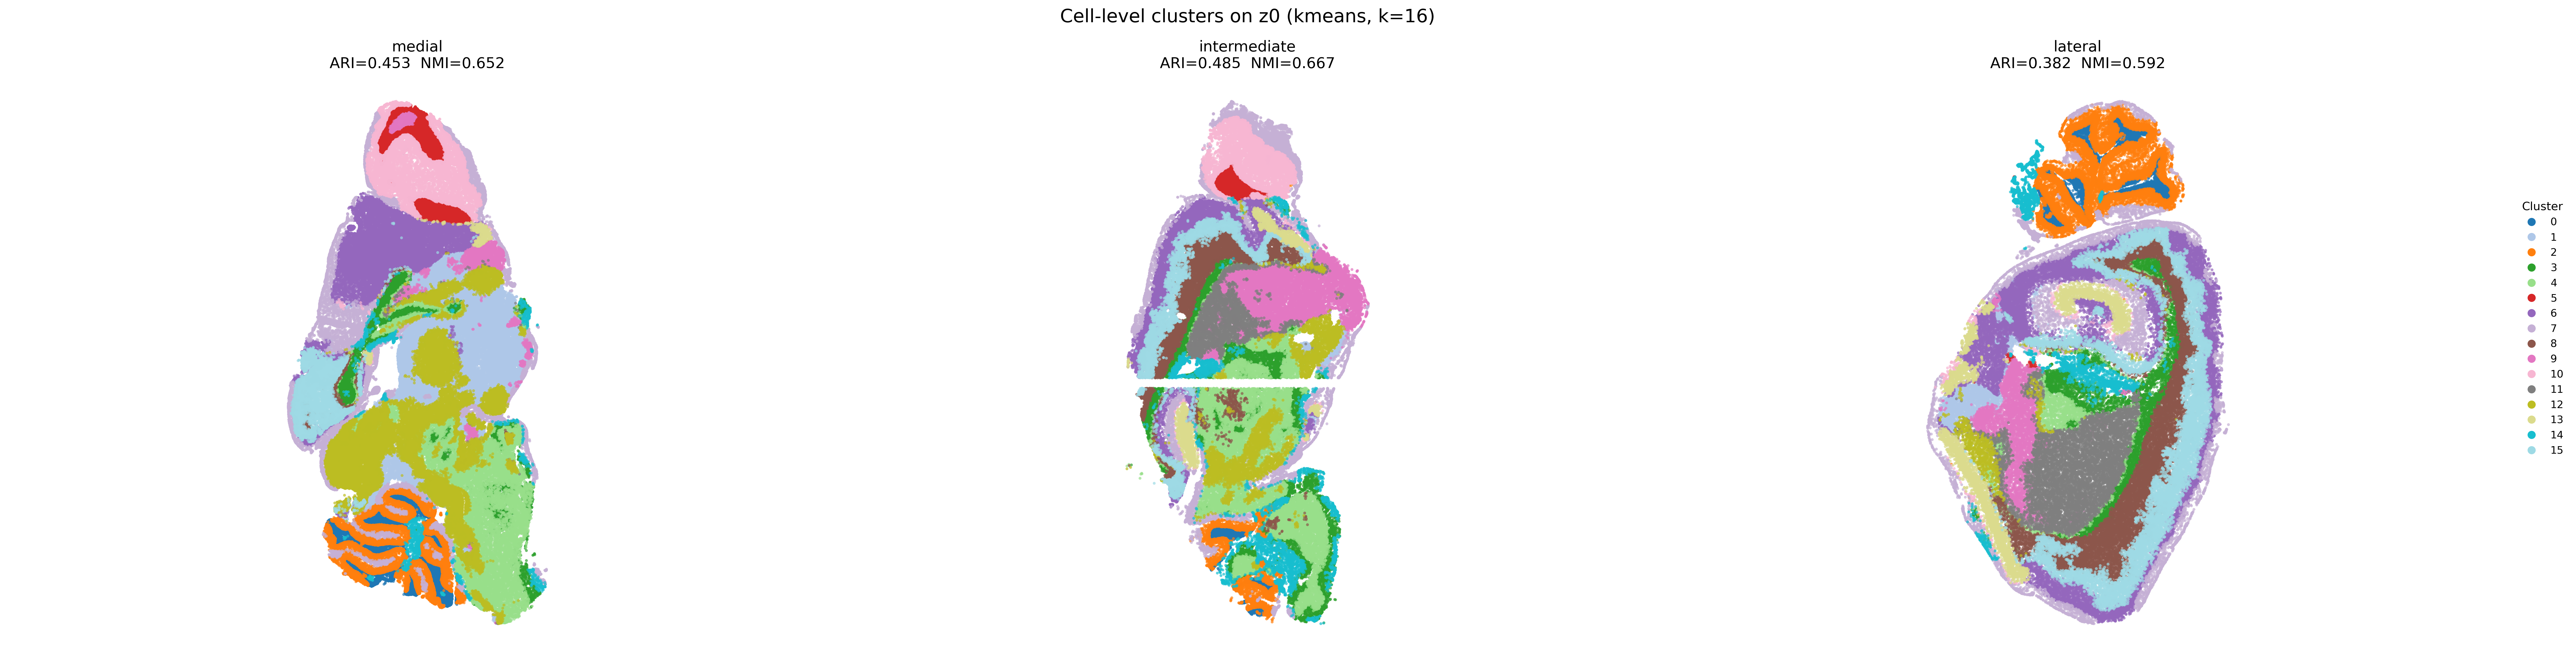

In [11]:
from IPython.display import Image, display

display(Image(filename=str(RESULTS_DIR / f"{written['cell_clusters']}.png")))

section 0: 17 in use | missing: ['13']
section 1: 18 in use | missing: []
section 2: 18 in use | missing: []


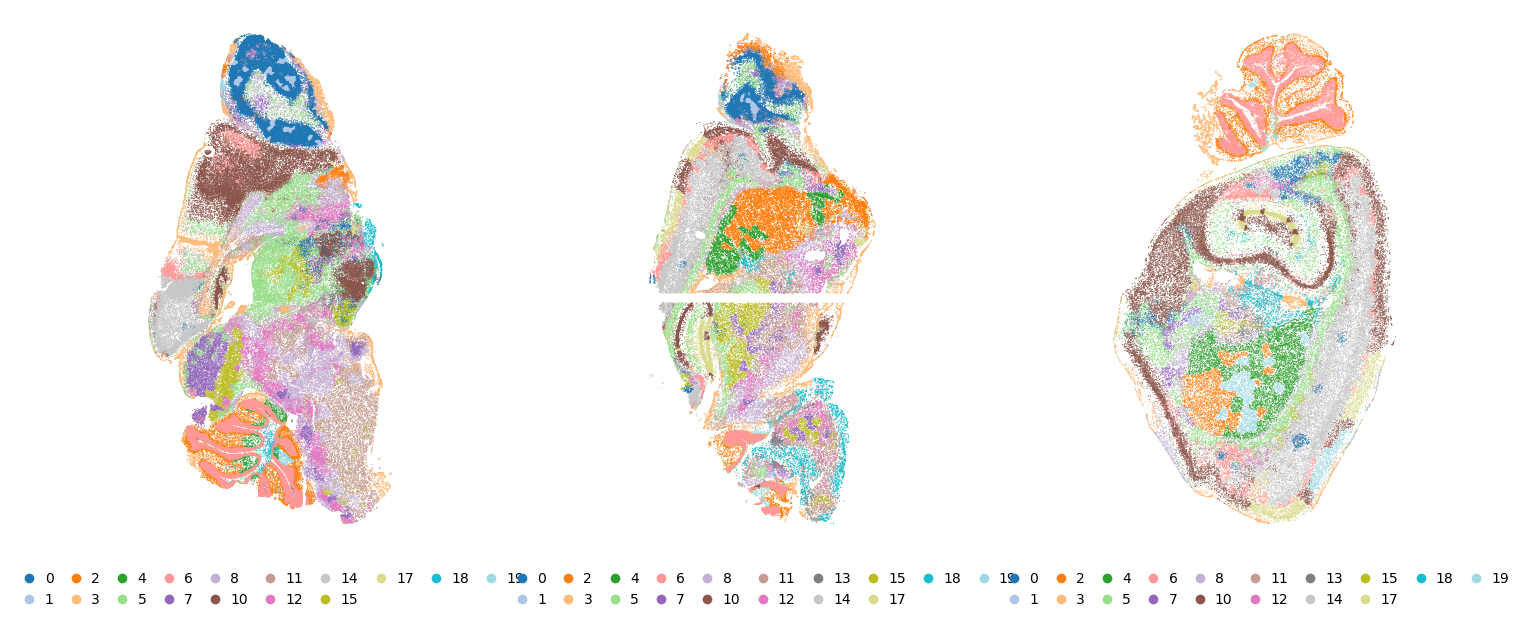

            section 0  section 1  section 2
prototypes                                 
0               33484      11676       2689
1                4181        826        375
2                8342      15448       8040
3               12097       8303       4497
4                1432       4446       5851
5               18820       8594       9773
6               37681      12749      14384
7                6835       3130        862
8               18332       8053       2511
10              23430       7080      16876
11              10283       9206       1070
12              12988       5999       1191
13                  0        858        477
14               8428      11690      13139
15               6195       4556        818
17               2516       6747       4368
18               1955       3614       1585
19                592        861       2740


In [12]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib, pandas as pd, numpy as np
from matplotlib.lines import Line2D
%matplotlib inline

proto_key = "prototypes"
cats = sorted(set().union(*[set(a.obs[proto_key].astype(str)) for a in sections]),
              key=lambda s: (len(s), s))
cmap = plt.get_cmap("tab20" if len(cats) <= 20 else "gist_ncar", len(cats))
colors = [matplotlib.colors.to_hex(cmap(i)) for i in range(len(cats))]
col_of = dict(zip(cats, colors))

for a in sections:
    a.obs[proto_key] = pd.Categorical(a.obs[proto_key].astype(str), categories=cats)
    a.uns[f"{proto_key}_colors"] = colors

fig, axes = plt.subplots(1, len(sections), figsize=(6 * len(sections), 7))
for i, (a, ax) in enumerate(zip(sections, axes)):
    present = [c for c in cats if (a.obs[proto_key] == c).any()]
    missing = [c for c in cats if c not in present]
    print(f"section {i}: {len(present)} in use | missing: {missing}")
    sc.pl.embedding(a, basis="spatial", color=proto_key, s=2, frameon=False,
                    title="", ax=ax, show=False, legend_loc=None)
    ax.set_aspect("equal")
    handles = [Line2D([], [], marker="o", ls="", ms=7, mfc=col_of[c], mew=0, label=c)
               for c in present]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.02),
              ncol=min(len(present), 10), frameon=False, fontsize=10,
              handletextpad=0.1, columnspacing=0.6)

out = RESULTS_DIR / f"{proto_key}_3sections_perlegend.png"
plt.savefig(out, dpi=300, bbox_inches="tight")
plt.savefig(out.with_suffix(".svg"), bbox_inches="tight")
plt.show()

# presence table: number of cells of each prototype per section
tab = pd.DataFrame({f"section {i}": a.obs[proto_key].value_counts().reindex(cats)
                    for i, a in enumerate(sections)}).fillna(0).astype(int)
print(tab)

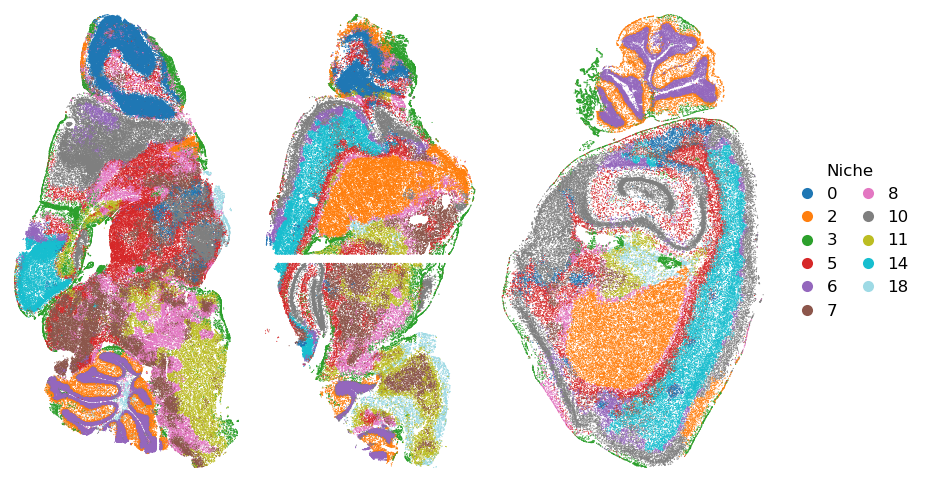

In [20]:
from matplotlib.lines import Line2D

KEY, HEIGHT, GAP, POINT_SIZE = NEW_KEY2, 6.0, 0.06, 0.6
plt.rcParams["font.family"] = "DejaVu Sans"; plt.rcParams["svg.fonttype"] = "none"

cats = sorted(set().union(*[set(a.obs[KEY].astype(str)) for a in sections]), key=lambda s: (len(s), s))
cmap = plt.get_cmap("tab20" if len(cats) <= 20 else "gist_ncar", len(cats))
col_of = {c: cmap(i) for i, c in enumerate(cats)}

fig, ax = plt.subplots(); x0 = 0.0
for a in sections:
    xy = np.asarray(a.obsm["spatial"])[:, :2].astype(float)
    xy -= xy.min(0); xy /= np.ptp(xy[:, 1])
    ax.scatter(xy[:, 0] + x0, xy[:, 1], c=[col_of[v] for v in a.obs[KEY].astype(str)],
               s=POINT_SIZE, linewidths=0, rasterized=True)
    x0 += xy[:, 0].max() + GAP
total = x0 - GAP
ax.set_xlim(-0.01, total + 0.01); ax.set_ylim(-0.01, 1.01)
ax.set_aspect("equal"); ax.axis("off"); fig.set_size_inches(HEIGHT * total, HEIGHT)
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=8, mfc=col_of[c], mew=0, label=c) for c in cats],
          loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=12,
          ncol=int(np.ceil(len(cats) / 10)), handletextpad=0.2, columnspacing=0.8,
          title="Niche", title_fontsize=12)

for fmt in ("png", "svg", "pdf"):
    fig.savefig(OUT / f"{KEY}_tight.{fmt}", dpi=300, bbox_inches="tight", pad_inches=0.05, facecolor="white")
plt.show()

### Trying other numbers

Because encoding already happened, changing the cluster count costs
seconds. Each call writes new columns and new figures rather than
replacing the old ones, so results can be compared side by side.

In [13]:
written_24 = cluster_sections(
    sections, ctx,
    n_cell_clusters=24,
    n_composition_niches=12,
    composition_neighbors=200,
    cell_type_key=ANNOTATION,
    niche_key=ANNOTATION,
    point_size=6,
)
print("\nwritten:", written_24)
print()
print("all clusterings now on the object:")
for col in sections[0].obs.columns:
    if col.startswith(("z0_", "comp_niches_", "prototypes")):
        print("  ", col)


Cell-level clustering: kmeans, k=24  ->  obs['z0_kmeans_24']
Niche-level clustering: 12 niches from 200-neighbour composition  ->  obs['comp_niches_12']

medial
  z0_kmeans_24           ARI=0.4430  NMI=0.6645  FIDE=0.9017
  prototypes             ARI=0.1847  NMI=0.3668  FIDE=0.8047
  comp_niches_12         ARI=0.2337  NMI=0.3960  FIDE=0.9530
intermediate
  z0_kmeans_24           ARI=0.4749  NMI=0.6894  FIDE=0.9023
  prototypes             ARI=0.2540  NMI=0.3983  FIDE=0.8044
  comp_niches_12         ARI=0.2761  NMI=0.4186  FIDE=0.9593
lateral
  z0_kmeans_24           ARI=0.3702  NMI=0.6036  FIDE=0.8940
  prototypes             ARI=0.3174  NMI=0.3966  FIDE=0.8520
  comp_niches_12         ARI=0.3029  NMI=0.3673  FIDE=0.9686

  24 categories exceeds tab20's 20 colours — using turbo
  Saved z0_kmeans_24 (s=6.0)
  Saved comp_niches_12 (s=6.0)

written: {'cell_clusters': 'z0_kmeans_24', 'composition_niches': 'comp_niches_12'}

all clusterings now on the object:
   prototypes
   z0_kmeans_16


One caution. Choosing the number of clusters by whichever gives the
highest ARI means selecting on the signal you then report, which
overstates performance. Use the annotation to sanity-check that the
labels are sensible, and choose the number from what you expect to
resolve, or from a section held out from the comparison.

`composition_neighbors` is worth varying too. It sets how much
surrounding tissue defines a niche — 200 neighbours covers a much larger
area on a sparse section than on a dense one, the same way `k` does.

### Are the niches consistent across sections?

This is the claim joint encoding makes, and it is worth checking rather
than assuming. If a label means the same thing everywhere, the same
annotated region should map to the same niche in every section it
appears in.

In [ ]:
import pandas as pd

niche_col = written["cell_clusters"]

table = pd.concat(
    [pd.crosstab(a.obs[ANNOTATION], a.obs[niche_col]).idxmax(axis=1).rename(lbl)
     for lbl, a in zip(LABELS, sections)],
    axis=1,
)
print(f"Dominant {niche_col} per annotated region:\n")
print(table.to_string())

Regions present in more than one section should map to the same niche.
Where they do not, it is usually because the region is small in one
section, or because a composite label covers structures that genuinely
differ along the medial-lateral axis.

## 7. Stage three: gene regulatory analysis

`grn=True` in stage one built a gene-interaction graph combining curated
priors — signalling and metabolic pathways, ligand-receptor pairs,
transcription-factor targets — with co-expression measured from the data.
A refinement layer learned an attention over that graph, trained by
masked gene-expression prediction, so the attention is
expression-predictive rather than arbitrary.

Because attention is normalised over each target gene's incoming edges,
it says which regulator wins the competition for a target, not how strong
the interaction is in absolute terms.

**The grouping is your choice.** `cluster_key` can be any column: a
discovered clustering from stage two, or an annotation. Interactions
between annotated cell types are a conventional analysis any method could
run; interactions between discovered niches are what this
representation adds. Use whichever matches the claim you want to make.

In [13]:
from hebi.inference.pipeline import analyse_grn

analyse_grn(
    sections, ctx,
    cluster_key="Main_molecular_tissue_region",
    top_k_edges=5,
    run_report=True,   # per-section hub genes, salience, and tables
    run_ccc=True,
)


GRN analysis, grouped by 'Main_molecular_tissue_region'
  29 interactions across 16 groups -> starmap_tutorial_n/results/grn_top5_medial

  GRN report -> starmap_tutorial_n/results/starmap_plus_mouse_cns_section_1_plot/grn
  Excluding 442 reverse-only copies from the report

GLOBAL PRE-CLUSTERING GRN REPORT

[1] Top edges by attention
source_gene target_gene  attention     edge_types  curated
       GAD1        GNG4   0.897977       spearman    False
       TAL1         MBP   0.888852      tf_target     True
      PRKCG       RRAS2   0.882867        pathway     True
       GNG4       MEIS2   0.683143       spearman    False
        FOS        HRH1   0.657668      tf_target     True
       IGF2       S1PR1   0.822176        pathway     True
      SPARC       PDGFA   0.520177         ligrec     True
        CCK       CCKBR   0.510238 pathway|ligrec     True
      KITLG         KIT   0.746013 pathway|ligrec     True
      GATA3    CACNA2D1   0.744822      tf_target     True
      PRKCG  

In [14]:
import pandas as pd, numpy as np
base = "starmap_tutorial_n/results/starmap_plus_mouse_cns_section_{}_plot/grn/starmap_plus_mouse_cns_section_{}_edges.csv"
for k, l in zip([1, 2, 3], ["medial", "intermediate", "lateral"]):
    e = pd.read_csv(base.format(k, k))
    n_reg = e.groupby("target_gene")["source_gene"].transform("nunique")
    x, y = 1 / n_reg, e["attention"]
    r2 = np.corrcoef(x, y)[0, 1] ** 2
    print(f"{l:<13} edges={len(e)}  R2(attention ~ 1/n_regulators) = {r2:.2f}")

medial        edges=625  R2(attention ~ 1/n_regulators) = 0.77
intermediate  edges=639  R2(attention ~ 1/n_regulators) = 0.76
lateral       edges=625  R2(attention ~ 1/n_regulators) = 0.76


In [15]:
import os

section_name = section_files[0].replace(".pt", "")
grn_dir = RESULTS_DIR / f"{section_name}_plot" / "grn"
print(f"{LABELS[0]} -> {grn_dir}\n")
for name in sorted(os.listdir(grn_dir)):
    print(" ", name)

medial -> starmap_tutorial_n/results/starmap_plus_mouse_cns_section_1_plot/grn

  Global_buble.png
  ccc_niche_specific.png
  ccc_whole_tissue.png
  niche_edge_activity.csv
  niche_grn_heatmap.png
  starmap_plus_mouse_cns_section_1_edge_type_attention.png
  starmap_plus_mouse_cns_section_1_edge_types.csv
  starmap_plus_mouse_cns_section_1_edges.csv
  starmap_plus_mouse_cns_section_1_edges_ranked_competitive.csv
  starmap_plus_mouse_cns_section_1_niche_edge_matrix.csv
  starmap_plus_mouse_cns_section_1_niche_grn_heatmap_clean.png
  starmap_plus_mouse_cns_section_1_nodes.csv
  starmap_plus_mouse_cns_section_1_top_edges_bar.png
  starmap_plus_mouse_cns_section_1_top_genes_bar.png


Each section gets its own folder holding the full report: hub genes
ranked by total attention over their incident edges, edge salience
corrected for how many regulators compete for each target, and the
underlying tables as CSV. `niche_edge_activity.csv` is the matrix behind
the heatmap below, so it can be re-plotted or analysed directly.

The two summary figures — the heatmap and the chord diagram — are written
once at the top level, since they compare across sections.

### Regulatory activity per niche

The heatmap shows the five strongest interactions in each niche. An
edge's activity in a group is its attention weighted by how strongly both
genes are expressed there, so an interaction is active when it is
favoured by the attention *and* both genes are present.

Values are scaled per row, so the colour shows where an interaction is
most active rather than how large its raw score is. Without that, a few
high-expression edges dominate every row and the niche structure
disappears.

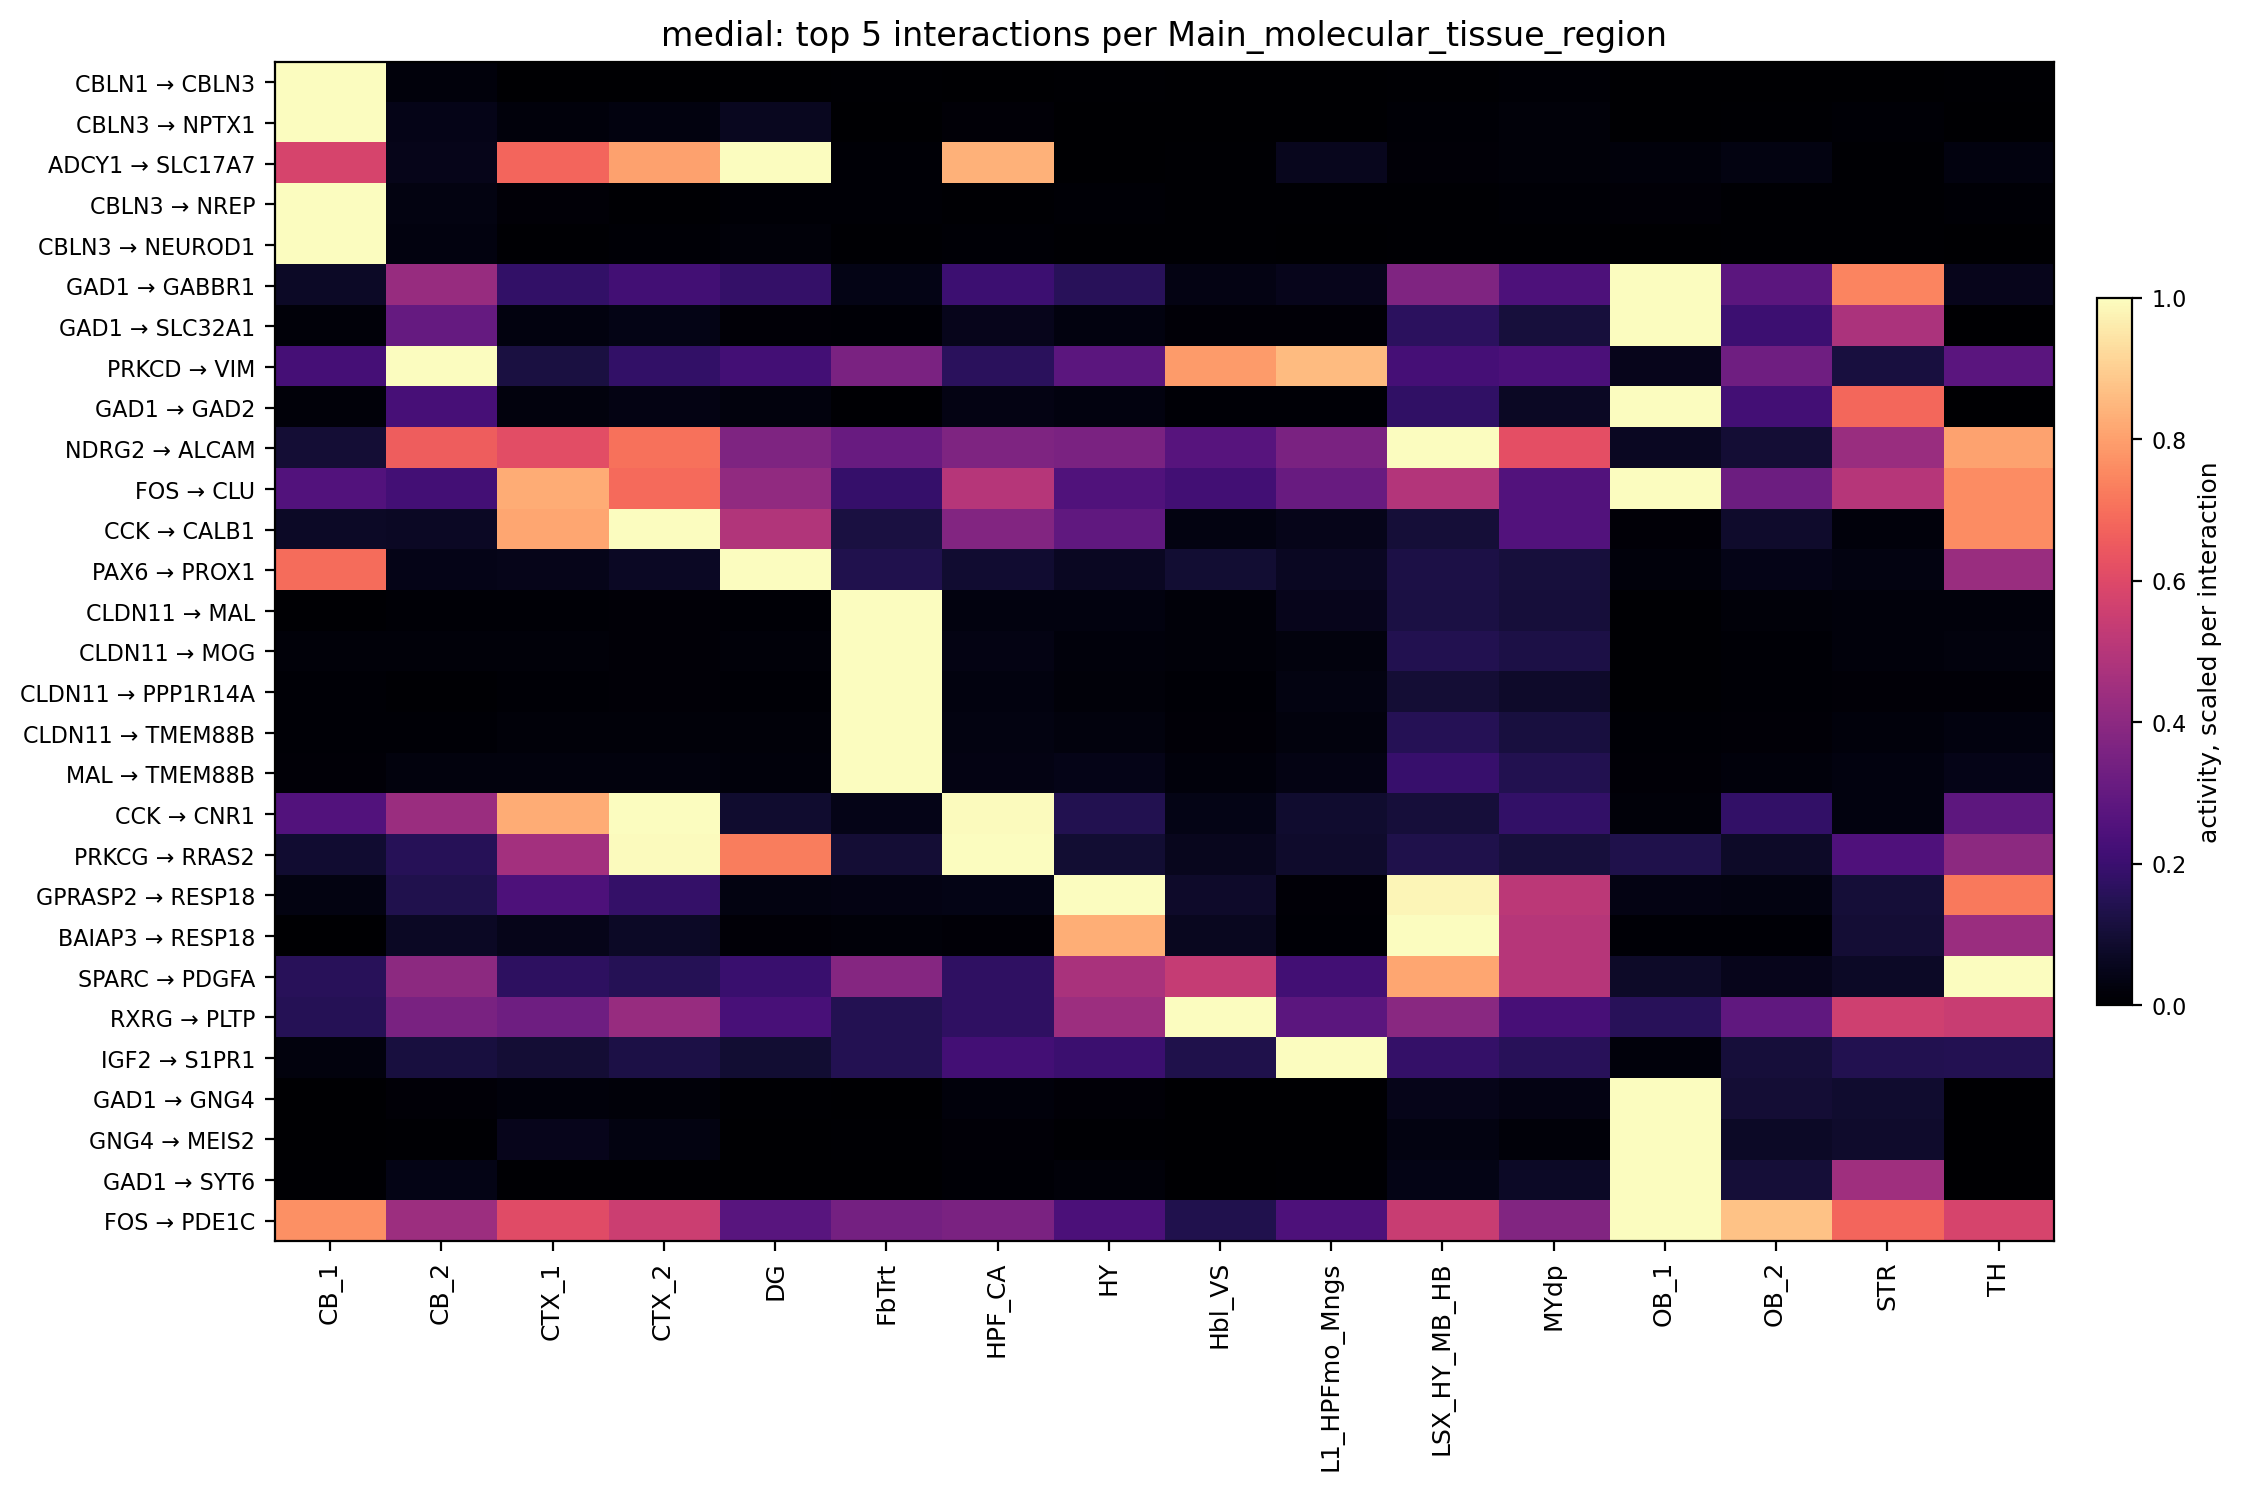

In [16]:
display(Image(filename=str(RESULTS_DIR / f"grn_top5_{LABELS[0]}.png")))

### Cell-cell communication

Ligand-receptor communication between the same groups, scored as
attention times ligand expression in the sender times receptor expression
in the receiver.

The full table is exported unfiltered, one sheet per section, so
downstream analyses see everything. The chord diagram is filtered for
legibility: with 16 groups there are 240 possible directed links, and
drawing them all produces an unreadable figure. Three filters apply to
the figure only — saturated edges are dropped, links below 15% of the
strongest are removed, and the top 18 are kept.

Saturated edges are worth understanding. Attention is normalised over
each target's incoming edges, so a receptor with a single regulator gets
an attention of exactly 1.0 by construction. Its score is then purely
expression-driven and carries no learned signal.

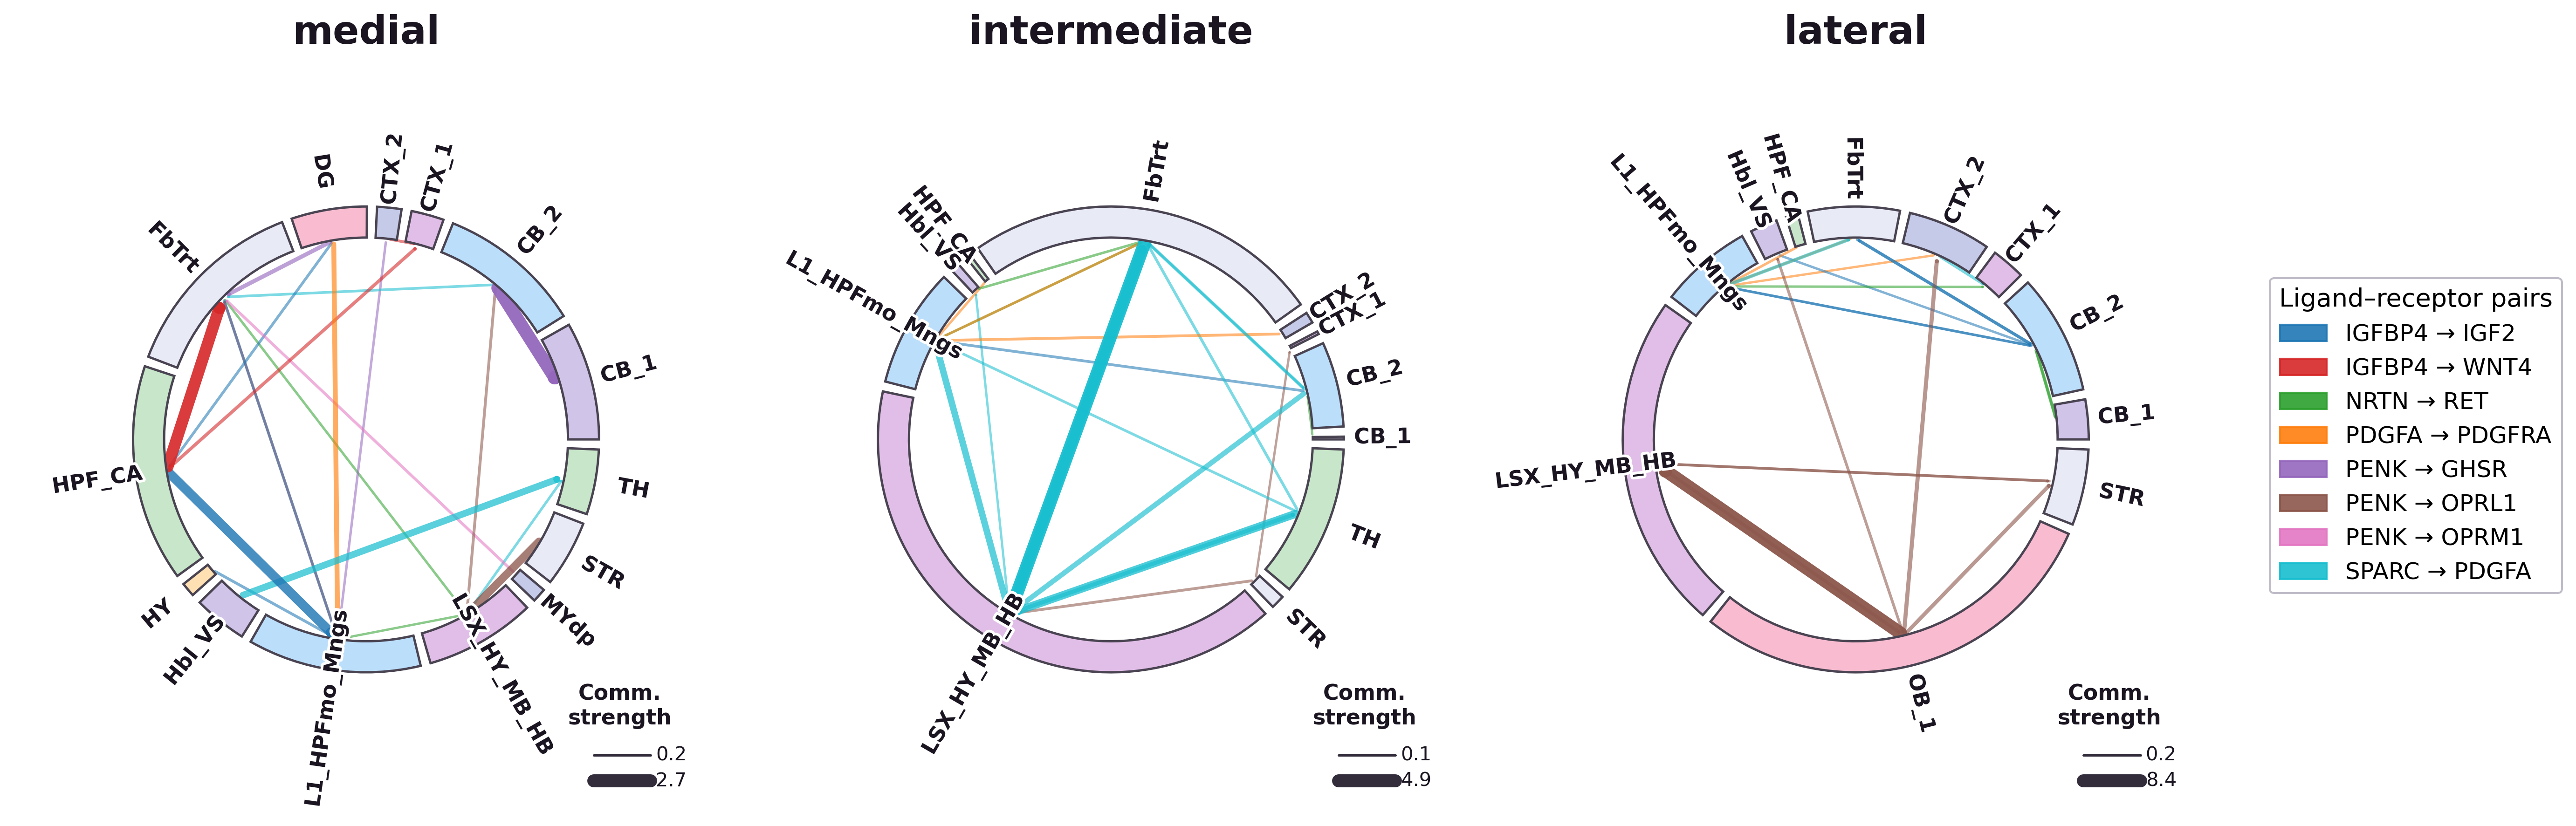

In [17]:
display(Image(filename=str(RESULTS_DIR / "ccc_chord.png")))

In [29]:
ccc = pd.read_excel(RESULTS_DIR / "CCC_all_pairs.xlsx", sheet_name=LABELS[0])
print(f"{len(ccc):,} sender-receiver links tested in the {LABELS[0]} section")

# Report links that are significant and at least twofold enriched at the
# boundary between the two niches.
reported = ccc[(ccc["fdr"] < 0.05) & (ccc["enrichment"] >= 2)]
print(f"{len(reported):,} reported (FDR < 0.05, enrichment >= 2)\n")

print(reported.sort_values("score", ascending=False).head(10)
      [["pair", "sender", "receiver", "score", "enrichment", "fdr"]]
      .round(3).to_string(index=False))

8,040 sender-receiver links tested in the medial section
933 reported (FDR < 0.05, enrichment >= 2)

          pair sender      receiver  score  enrichment  fdr
   PENK → GHSR   CB_2          CB_1  2.713       2.127  0.0
 IGFBP4 → WNT4 HPF_CA         FbTrt  2.406      10.305  0.0
   CCK → CCKBR  CTX_2         CTX_1  2.052       5.385  0.0
 IGFBP4 → IGF2 HPF_CA L1_HPFmo_Mngs  1.846       8.916  0.0
 IGFBP4 → WNT4 HPF_CA L1_HPFmo_Mngs  1.607       8.125  0.0
  PENK → OPRL1    STR  LSX_HY_MB_HB  1.523       3.369  0.0
 SPARC → PDGFA Hbl_VS            TH  1.230       2.378  0.0
    NRTN → RET   CB_2          CB_1  0.899       3.724  0.0
PDGFA → PDGFRA HPF_CA         FbTrt  0.821       2.834  0.0
PDGFA → PDGFRA     DG L1_HPFmo_Mngs  0.806       2.968  0.0


If most of the table turns out to be saturated, that is worth knowing: it
means the gene-interaction graph has many receptors with only one
regulator, so those interactions are scored on expression alone. Building
the graph from a larger gene panel, or lowering the co-expression
threshold, gives receptors more competing regulators and makes the
attention more informative.

## 8. Applying this to your own sections

The steps are the same. Five things change.

**The annotation column.** `cell_type_key` and `niche_key` name columns
in your `obs`. Leave them out if your data is unannotated — everything
still runs, and FIDE is reported instead of ARI and NMI.

**`k`.** Run the diagnostic in section 3 on one of your sections. The
reach in cell diameters is what transfers between datasets, not the value
of `k` itself.

**The counts layer.** `counts_layer="raw"` suits these files. The name
varies between exports; preprocessing prints the available layers if the
name is wrong, and prints what it found if you pass nothing.

**Cluster and niche counts.** Set from what you expect to resolve. Stage
two is cheap, so try several.

**Species.** Affects both gene harmonisation and which curated priors the
GRN step retrieves.

Two things that do not change. Sections must be encoded together to get
comparable labels. And the `.pt` files fix which cells exist and in what
order, so the AnnData passed in must contain the same cells — the
pipeline checks this by coordinate and stops if they disagree.

### The same run from the command line

```bash
hebi-preprocess \
  --h5ad section_1.h5ad --out_root processed/ \
  --vocab_path default_gene_vocab.json \
  --k 30 --species Mouse --counts_layer raw

hebi-run --config configs/starmap.yaml --grn --grn_ccc
```

Putting the settings in a YAML file rather than passing flags keeps a
record of what produced a given set of results.

In [30]:
BASE =  RESULTS_DIR
LABELS = ["medial", "intermediate", "lateral"]

mats = {}
for i, s in enumerate(LABELS, start=1):
    d = f"{BASE}/starmap_plus_mouse_cns_section_{i}_plot/grn"
    m = pd.read_csv(f"{d}/starmap_plus_mouse_cns_section_{i}_niche_edge_matrix.csv", index_col=0)
    e = pd.read_csv(f"{d}/starmap_plus_mouse_cns_section_{i}_edges.csv")
    learned = set((e.source_gene + "→" + e.target_gene)[e.attention < 0.99])
    mats[s] = m[m.index.isin(learned)]
    print(f"{s}: {m.shape[0]} edges -> {mats[s].shape[0]} with learned attention")

medial: 625 edges -> 513 with learned attention
intermediate: 639 edges -> 529 with learned attention
lateral: 625 edges -> 509 with learned attention


In [31]:
import pandas as pd, numpy as np

gdir = lambda i: RESULTS_DIR / f"starmap_plus_mouse_cns_section_{i}_plot" / "grn"
mat = {s: pd.read_csv(gdir(i) / f"starmap_plus_mouse_cns_section_{i}_niche_edge_matrix.csv", index_col=0)
       for i, s in enumerate(LABELS, 1)}

# edges with learned attention (< 0.99) in all three sections
learned = []
for i in (1, 2, 3):
    e = pd.read_csv(gdir(i) / f"starmap_plus_mouse_cns_section_{i}_edges.csv")
    learned.append(set((e.source_gene + "→" + e.target_gene)[e.attention < 0.99]))
shared = set.intersection(*learned)

# niches present in all three sections only: a gradient needs all three values
common = sorted(set.intersection(*[set(m.columns) for m in mat.values()]))

rows = []
for niche in common:
    df = pd.DataFrame({s.capitalize(): mat[s].loc[mat[s].index.isin(shared), niche] for s in LABELS}).dropna()
    m, i_, l = df["Medial"], df["Intermediate"], df["Lateral"]
    df["max_diff"] = df.max(axis=1) - df.min(axis=1)
    df["monotonic"] = ((m < i_) & (i_ < l)) | ((m > i_) & (i_ > l))
    df["niche"] = niche
    rows.append(df.sort_values("max_diff", ascending=False).head(10))

gradients = pd.concat(rows).rename_axis("edge").reset_index()
gradients.to_csv(RESULTS_DIR / "grn_gradients_top10_per_niche.csv", index=False)
for niche, d in gradients.groupby("niche", sort=False):
    print(f"\n=== {niche} ===")
    print(d.drop(columns="niche").round(2).to_string(index=False))


=== CB_1 ===
         edge  Medial  Intermediate  Lateral  max_diff  monotonic
CBLN3→NEUROD1    7.45          8.38     6.61      1.77      False
   CBLN3→FAT2    7.31          8.70     7.02      1.68      False
   CBLN1→FAT2    5.46          6.34     5.93      0.89      False
 FAT2→NEUROD1    3.21          3.83     3.16      0.67      False
CBLN1→NEUROD1    4.48          4.92     4.50      0.44      False
    PRKCD→VIM    0.58          0.41     0.78      0.37      False
      FOS→CLU    0.67          0.52     0.72      0.20      False
  SPARC→PDGFA    0.41          0.30     0.24      0.17       True
     TAL1→MBP    0.24          0.12     0.13      0.12      False
  S1PR1→ADCY1    0.19          0.16     0.27      0.11      False

=== CB_2 ===
         edge  Medial  Intermediate  Lateral  max_diff  monotonic
  NDRG2→ALCAM    1.95          1.14     1.02      0.93       True
  SPARC→PDGFA    1.04          0.71     0.38      0.66       True
    PRKCD→VIM    2.60          2.74     3.07    

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Typography and export settings
plt.rcParams['svg.fonttype'] = 'none'          # editable text in Illustrator/Inkscape
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['font.size'] = 17
plt.rcParams['axes.titlesize'] = 19
plt.rcParams['axes.labelsize'] = 17
plt.rcParams['xtick.labelsize'] = 17
plt.rcParams['ytick.labelsize'] = 17


def learned_edges(edges_csv, max_attention=0.99):
    """Edges whose target has competing regulators (attention < 1).
    Saturated edges (single regulator, attention = 1) are expression-only."""
    e = pd.read_csv(edges_csv)
    e = e[e["attention"] < max_attention]
    return set(e["source_gene"] + "→" + e["target_gene"])


def get_monotonic_gradients(file_medial, file_inter, file_lateral, keep_edges=None,
                            min_diff=0.5, top_n=15):
    """Niche-edge pairs whose activity changes monotonically from medial to
    lateral, in niches present in all three sections, ranked by |medial - lateral|."""
    df_medial = pd.read_csv(file_medial, index_col=0)
    df_inter = pd.read_csv(file_inter, index_col=0)
    df_lateral = pd.read_csv(file_lateral, index_col=0)
    if keep_edges is not None:
        df_medial = df_medial[df_medial.index.isin(keep_edges)]
        df_inter = df_inter[df_inter.index.isin(keep_edges)]
        df_lateral = df_lateral[df_lateral.index.isin(keep_edges)]
    common_niches = set(df_medial.columns) & set(df_inter.columns) & set(df_lateral.columns)

    records = []
    for niche in common_niches:
        niche_df = pd.DataFrame({'Medial': df_medial[niche],
                                 'Intermediate': df_inter[niche],
                                 'Lateral': df_lateral[niche]}).dropna()
        inc = (niche_df['Medial'] < niche_df['Intermediate']) & (niche_df['Intermediate'] < niche_df['Lateral'])
        dec = (niche_df['Medial'] > niche_df['Intermediate']) & (niche_df['Intermediate'] > niche_df['Lateral'])
        mono = niche_df[inc | dec].copy()
        mono['Abs_Diff'] = (mono['Medial'] - mono['Lateral']).abs()
        for edge, row in mono.iterrows():
            if row['Abs_Diff'] > min_diff:
                records.append({'Niche_Edge': f"{niche}\n{edge}",
                                'Medial': row['Medial'],
                                'Intermediate': row['Intermediate'],
                                'Lateral': row['Lateral'],
                                'Abs_Diff': row['Abs_Diff']})

    results_df = pd.DataFrame(records)
    if not results_df.empty:
        results_df = (results_df.sort_values('Abs_Diff', ascending=False).head(top_n)
                      .set_index('Niche_Edge').drop(columns='Abs_Diff'))
    return results_df


def plot_horizontal_gradient_heatmap(df, output_path):
    # row-wise z-score: colour shows where each interaction is strongest
    df_z = (df - df.mean(axis=1).values.reshape(-1, 1)) / df.std(axis=1).values.reshape(-1, 1)

    cmap = LinearSegmentedColormap.from_list("diverging", ["#722F37", "#F7F7F7", "#005B4B"], N=256)

    plt.figure(figsize=(26, 6))
    ax = sns.heatmap(df_z.T, cmap=cmap, annot=False,           # no cell annotations
                     linewidths=2, linecolor='white',
                     cbar_kws={"shrink": 0.75, "label": "Row z-score", "pad": 0.02})
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.tight_layout()
    plt.savefig(output_path, format='svg', dpi=300, bbox_inches='tight')
    plt.show()
    print(f"saved {output_path}")


# Run
gdir = lambda i: RESULTS_DIR / f"starmap_plus_mouse_cns_section_{i}_plot" / "grn"
f_med, f_int, f_lat = [gdir(i) / f"starmap_plus_mouse_cns_section_{i}_niche_edge_matrix.csv" for i in (1, 2, 3)]
edge_files = [gdir(i) / f"starmap_plus_mouse_cns_section_{i}_edges.csv" for i in (1, 2, 3)]

shared = set.intersection(*[learned_edges(f) for f in edge_files])
print("edges learned in all three sections:", len(shared))

gradient_edges = get_monotonic_gradients(f_med, f_int, f_lat, keep_edges=shared)
print(len(gradient_edges), "niche-edge gradients selected")
gradient_edges.to_csv(RESULTS_DIR / "spatial_gradients_selected.csv")

plot_horizontal_gradient_heatmap(gradient_edges, RESULTS_DIR / "spatial_gradient_heatmap_nature.svg")

edges learned in all three sections: 491
15 niche-edge gradients selected
saved starmap_tutorial_n/results/spatial_gradient_heatmap_nature.svg


In [33]:
# Rule: largest monotonic medial-lateral gradient per niche (|medial - lateral|),
# no edge repeated across panels, four panels.
g = pd.read_csv(RESULTS_DIR / "grn_gradients_top10_per_niche.csv")
g = g[g["monotonic"]].assign(delta=lambda d: (d["Lateral"] - d["Medial"]).abs())
NICHE_EDGES, used = {}, set()
for _, r in g.sort_values("delta", ascending=False).iterrows():
    if r["niche"] in NICHE_EDGES or r["edge"] in used:
        continue
    NICHE_EDGES[r["niche"]] = r["edge"]; used.add(r["edge"])
    print(f"{r['niche']:<8} {r['edge']:<14} {r['Medial']:.2f} -> {r['Intermediate']:.2f} -> {r['Lateral']:.2f}")
    if len(NICHE_EDGES) == 4:
        break

OB_1     NDRG2→ALCAM    0.19 -> 0.19 -> 3.06
STR      PRKCG→RXRG     1.12 -> 1.73 -> 2.85
Hbl_VS   PRKCD→VIM      2.05 -> 0.46 -> 0.36
HPF_CA   CCK→CNR1       1.32 -> 1.46 -> 2.49


In [34]:
import scanpy as sc, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']


def niche_grn_per_cell(niche, mat, edge):
    """Per-cell value: the niche-level activity of `edge` in the cell's niche."""
    row = mat.loc[edge] if edge in mat.index else pd.Series(0.0, index=mat.columns)
    return np.array([float(row.get(n, 0.0)) for n in niche])


def pastel(c, amount=0.88):
    r, g, b = to_rgb(c)
    return (r + (1 - r) * amount, g + (1 - g) * amount, b + (1 - b) * amount)


cluster_key = "Main_molecular_tissue_region"

# Monotonic medial-lateral gradients (activity: medial, intermediate, lateral)
NICHE_EDGES = {
    "OB_1":   "NDRG2→ALCAM",  # 0.19 -> 0.19 -> 3.06  (increase)
    "STR":    "PRKCG→RXRG",   # 1.12 -> 1.73 -> 2.85  (increase)
    "Hbl_VS": "PRKCD→VIM",    # 2.05 -> 0.46 -> 0.36  (decrease)
    "HPF_CA": "CCK→CNR1",     # 1.32 -> 1.46 -> 2.49  (increase)
}

order = ["Medial", "Intermediate", "Lateral"]
z_pos = {"Medial": 0.0, "Intermediate": 4.0, "Lateral": 8.0}
SPOT, CMAP = 0.8, "cool"

gdir = lambda i: RESULTS_DIR / f"starmap_plus_mouse_cns_section_{i}_plot" / "grn"
loaded, all_regions = {}, set()
for i, (name, path) in enumerate(zip(order, H5AD_FILES), start=1):
    a = sc.read_h5ad(path)
    coords = np.asarray(a.obsm["spatial"], dtype=float)[:, :2]
    coords = (coords - coords.min(0)) / (np.ptp(coords, axis=0) + 1e-9)
    niche = a.obs[cluster_key].astype(str).values
    mat = pd.read_csv(gdir(i) / f"starmap_plus_mouse_cns_section_{i}_niche_edge_matrix.csv", index_col=0)
    loaded[name] = (coords, niche, mat)
    all_regions |= set(niche)
    del a

tab = plt.get_cmap("tab20")
region_pastel = {r: pastel(tab(i % 20)) for i, r in enumerate(sorted(all_regions))}

# per-cell values and a shared colour scale per niche across sections
scores, gmax = {}, {n: 0.0 for n in NICHE_EDGES}
for name in order:
    coords, niche, mat = loaded[name]
    scores[name] = {nic: niche_grn_per_cell(niche, mat, edge) for nic, edge in NICHE_EDGES.items()}
    for nic in NICHE_EDGES:
        if (niche == nic).any():
            gmax[nic] = max(gmax[nic], scores[name][nic][niche == nic].max())
print("per-niche max:", {k: round(v, 2) for k, v in gmax.items()})

fig = plt.figure(figsize=(28, 7.5), facecolor="white")
for idx, (TNICHE, EDGE) in enumerate(NICHE_EDGES.items()):
    ax = fig.add_subplot(1, 4, idx + 1, projection="3d")
    ax.set_facecolor("white")
    p = None
    for name in order:
        coords, niche, _ = loaded[name]
        x, y = coords[:, 0], coords[:, 1]
        z = np.full_like(x, z_pos[name])
        m = niche == TNICHE
        ax.scatter(x[~m], z[~m], y[~m], c=[region_pastel[n] for n in niche[~m]], s=SPOT,
                   alpha=0.45, rasterized=True, depthshade=False, zorder=1, edgecolors="none")
        if m.any():
            p = ax.scatter(x[m], z[m], y[m], c=scores[name][TNICHE][m], cmap=CMAP, s=SPOT,
                           vmin=0, vmax=gmax[TNICHE], alpha=1.0, rasterized=True,
                           depthshade=False, zorder=20, edgecolors="none")
        ax.plot([0, 1, 1, 0, 0], [z_pos[name]] * 5, [0, 0, 1, 1, 0], color="#cccccc", lw=0.6, alpha=0.4)

    ax.set_xticks([]); ax.set_zticks([])
    ax.set_yticks(list(z_pos.values())); ax.set_yticklabels(["M", "I", "L"], fontsize=12)
    ax.set_title(f"{TNICHE}\n{EDGE}", fontsize=18, fontweight="bold", pad=4)
    ax.view_init(elev=26, azim=-60)
    ax.set_box_aspect((1, 4, 1), zoom=1.4)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.set_alpha(0.0)
    ax.grid(False)
    if p is not None:
        cb = fig.colorbar(p, ax=ax, shrink=0.45, pad=0.02, aspect=25)
        cb.set_label("GRN activity", fontsize=12)
        cb.outline.set_visible(False)

plt.tight_layout()
for fmt in ("svg", "png"):
    plt.savefig(RESULTS_DIR / f"niche_multi_grn_3d_1x4.{fmt}", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

per-niche max: {'OB_1': np.float64(3.06), 'STR': np.float64(2.85), 'Hbl_VS': np.float64(2.05), 'HPF_CA': np.float64(2.49)}


In [64]:
import anndata as ad, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'DejaVu Sans'

cluster_key = "Main_molecular_tissue_region"
NICHE_EDGES = {
    "OB_1":   "NDRG2→ALCAM",  # 0.19 -> 0.19 -> 3.06  (increase)
    "STR":    "PRKCG→RXRG",   # 1.12 -> 1.73 -> 2.85  (increase)
    "Hbl_VS": "PRKCD→VIM",    # 2.05 -> 0.46 -> 0.36  (decrease)
    "HPF_CA": "CCK→CNR1",     # 1.32 -> 1.46 -> 2.49  (increase)
}
order = ["Medial", "Intermediate", "Lateral"]
GAP, SPOT_BG, SPOT_FG, CMAP = 0.3, 0.15, 0.6, "cool"
FONT = 17

# coordinates (aspect preserved, each section scaled to height 1), niches, activity matrices
gdir = lambda i: RESULTS_DIR / f"starmap_plus_mouse_cns_section_{i}_plot" / "grn"
secs = []
for i, path in enumerate(H5AD_FILES, start=1):
    a = ad.read_h5ad(path, backed="r")
    xy = np.asarray(a.obsm["spatial"], dtype=float)[:, :2]
    xy = (xy - xy.min(0)) / np.ptp(xy[:, 1])
    secs.append(dict(xy=xy, niche=a.obs[cluster_key].astype(str).values,
                     mat=pd.read_csv(gdir(i) / f"starmap_plus_mouse_cns_section_{i}_niche_edge_matrix.csv", index_col=0)))
    a.file.close()
from matplotlib.colors import to_rgb
def pastel(c, amount=0.88):
    r, g, b = to_rgb(c)
    return (r + (1 - r) * amount, g + (1 - g) * amount, b + (1 - b) * amount)
regions = sorted(set().union(*[set(s["niche"]) for s in secs]))
region_pastel = {r: pastel(plt.get_cmap("tab20")(i % 20)) for i, r in enumerate(regions)}
fig, axes = plt.subplots(1, len(NICHE_EDGES), figsize=(34, 5.6), facecolor="white",
                         gridspec_kw=dict(wspace=0.2), dpi=300)
for ax, (niche, edge) in zip(axes, NICHE_EDGES.items()):
    vals = [s["mat"].loc[edge, niche] if (edge in s["mat"].index and niche in s["mat"].columns) else np.nan
            for s in secs]
    vmax = np.nanmax(vals)
    x0, p = 0.0, None
    for s, v, lab in zip(secs, vals, order):
        xy, m = s["xy"], s["niche"] == niche
        ax.scatter(xy[~m, 0] + x0, xy[~m, 1], c=[region_pastel[n] for n in s["niche"][~m]],
                   s=SPOT_BG, linewidths=0, rasterized=True)
        if m.any():
            p = ax.scatter(xy[m, 0] + x0, xy[m, 1], c=np.full(m.sum(), v), cmap=CMAP, vmin=0, vmax=vmax,
                           s=SPOT_FG, linewidths=0, rasterized=True)
        w = xy[:, 0].max()
        ax.text(x0 + w / 2, 1.04, lab, ha="center", va="bottom", fontsize=FONT - 1)
        x0 += w + GAP
    ax.set_xlim(-0.02, x0 - GAP + 0.02); ax.set_ylim(-0.02, 1.14)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{niche}\n{edge}", fontsize=FONT + 2, fontweight="bold", pad=14)
    ax.p_handle = p


fig.subplots_adjust(left=0.01, right=0.97, top=0.80, bottom=0.03, wspace=0.12)

# colorbars placed from each panel's final position
for ax in axes:
    if getattr(ax, "p_handle", None) is None:
        continue
    pos = ax.get_position()
    cax = fig.add_axes([pos.x1 + 0.004, pos.y0 + pos.height * 0.25, 0.005, pos.height * 0.5])
    cb = fig.colorbar(ax.p_handle, cax=cax)
    cb.set_label("GRN activity", fontsize=FONT - 3); cb.ax.tick_params(labelsize=FONT - 4)
    cb.outline.set_visible(False)

fig.savefig(RESULTS_DIR / "niche_multi_grn_2d_1x4.svg", dpi=300, facecolor="white")   # no bbox_inches
fig.savefig(RESULTS_DIR / "niche_multi_grn_2d_1x4.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# ── Settings ─────────────────────────────────────────────────────────
EXCEL_PATH = RESULTS_DIR / "CCC_all_pairs.xlsx"
ORDER = ["medial", "intermediate", "lateral"]       # sheet names = section labels
TOP_N = 20                                          # rows used for the figure
SENSITIVITY_N = [10, 20, 50, 100, 200, 500, 1000]   # thresholds for the robustness check
CLASSES = ["neuronal", "glial/trophic", "mixed", "other"]
COLORS = {"neuronal": "#2166AC", "glial/trophic": "#C0392B",
          "mixed": "#9B7FB8", "other": "#D9D9D9"}

# ── Gene classification (by known function) ──────────────────────────
NEURONAL = {
    # opioid system
    "PENK", "PDYN", "PNOC", "POMC", "OPRD1", "OPRM1", "OPRK1", "OPRL1",
    # neuropeptides and their receptors
    "CCK", "CCKAR", "CCKBR", "SST", "NPY", "CRH", "ADCYAP1", "VIPR2", "NPFFR2", "GHSR",
    # neurotransmission and synapse
    "GRM5", "GRM7", "SLC17A7", "NPTX1", "GAD1", "SLC32A1", "GABBR1", "NRGN",
    # axon guidance
    "EFNA5", "EPHA7",
}
GLIAL_TROPHIC = {
    # matricellular and growth factors
    "PDGFA", "PDGFRA", "SPARC", "IGF2", "IGFBP4", "IGFBP2", "CLU", "VIM", "PLTP",
    # Wnt pathway modulators
    "WNT4", "FRZB", "RSPO3", "NOTUM",
    # neurotrophins and receptors
    "NTF3", "NTRK1", "NGFR", "NRTN", "RET",
    # vascular
    "ADM", "RAMP3",
    # guidance (glial/vascular context)
    "NRP2", "SEMA3F",
}
# ADRB3 left unclassified ("other")


def classify(pair):
    genes = {g.strip() for g in str(pair).split("→")}
    n = bool(genes & NEURONAL)
    g = bool(genes & GLIAL_TROPHIC)
    if n and not g:
        return "neuronal"
    if g and not n:
        return "glial/trophic"
    if n and g:
        return "mixed"
    return "other"


def top_interactions(df, n):
    """Attention-supported, between-niche interactions, strongest n rows.
    Saturated edges (attention = 1, receptor with a single regulator) are
    dropped, as in the chord diagram."""
    d = df[(df["sender"] != df["receiver"]) & (df["attention"] < 1 - 1e-6)]
    d = d.sort_values("score", ascending=False).head(n).copy()
    d["class"] = d["pair"].apply(classify)
    return d


def composition(df, n):
    d = top_interactions(df, n)
    f = d.groupby("class")["score"].sum()
    return (f / f.sum()).reindex(CLASSES).fillna(0)


# ── Load ─────────────────────────────────────────────────────────────
all_sheets = pd.read_excel(EXCEL_PATH, sheet_name=None)
missing = [s for s in ORDER if s not in all_sheets]
if missing:
    raise KeyError(f"Sheets {missing} not found; available: {list(all_sheets)}")
ccc = {s: all_sheets[s] for s in ORDER}

# ── Unclassified genes among the rows used for the figure ────────────
for s in ORDER:
    d = top_interactions(ccc[s], TOP_N)
    genes = {g.strip() for p in d["pair"] for g in str(p).split("→")}
    print(f"{s}: unclassified genes in top {TOP_N} ->",
          sorted(genes - NEURONAL - GLIAL_TROPHIC))

# ── Robustness: neuronal share across thresholds ─────────────────────
sens = pd.DataFrame({
    f"top {n}": {s: round(100 * composition(ccc[s], n)["neuronal"], 1) for s in ORDER}
    for n in SENSITIVITY_N
}).T
print("\nNeuronal share of communication score (%) by threshold:")
print(sens.to_string())

# ── Composition used in the figure ───────────────────────────────────
fr = pd.DataFrame({s: composition(ccc[s], TOP_N) for s in ORDER}).T
print(f"\nComposition (top {TOP_N}, %):")
print((fr * 100).round(1).to_string())

# ── Stacked barplot ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7.5, 5.5))
bottom = np.zeros(len(ORDER))

for cls in CLASSES:
    vals = fr[cls].values * 100
    ax.bar(range(len(ORDER)), vals, bottom=bottom, label=cls,
           color=COLORS[cls], edgecolor="white", width=0.65)
    for i, v in enumerate(vals):
        if cls in ("neuronal", "glial/trophic") and v > 4:
            ax.text(i, bottom[i] + v / 2, f"{v:.0f}%", ha="center", va="center",
                    color="white", fontsize=14, fontweight="bold")
    bottom += vals

ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([s.capitalize() for s in ORDER], fontsize=16)
ax.set_ylabel("Communication score (%)", fontsize=14, fontweight="bold")
ax.set_title(f"Composition of the top {TOP_N} interactions",
             fontsize=16, fontweight="bold", pad=15)
ax.set_ylim(0, 100)
ax.legend(bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2,
          fontsize=14, frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(f"pathway_composition_top{TOP_N}.svg", format="svg", dpi=300,
            bbox_inches="tight")
plt.show()

medial: unclassified genes in top 20 -> []
intermediate: unclassified genes in top 20 -> []
lateral: unclassified genes in top 20 -> []

Neuronal share of communication score (%) by threshold:
          medial  intermediate  lateral
top 10      14.6           5.9     52.5
top 20      18.6           7.4     44.9
top 50      21.0          11.3     42.3
top 100     27.3          16.2     42.2
top 200     31.7          21.2     43.5
top 500     32.8          26.4     44.4
top 1000    33.9          28.7     44.2

Composition (top 20, %):
class         neuronal  glial/trophic  mixed  other
medial            18.6           81.4    0.0    0.0
intermediate       7.4           90.7    1.9    0.0
lateral           44.9           55.1    0.0    0.0


In [42]:
import pandas as pd
all_sheets = pd.read_excel(RESULTS_DIR / "CCC_all_pairs.xlsx", sheet_name=None)
ORDER = ["medial", "intermediate", "lateral"]

tables = {}
for s in ORDER:
    d = all_sheets[s]
    d = d[(d.fdr < 0.05) & (d.enrichment >= 2)]          # reported links only
    total = d["score"].sum()
    g = (d.groupby("pair")
           .agg(score=("score", "sum"),
                attention=("attention", "first"),
                n_links=("score", "size"),
                top_sender=("sender", lambda x: d.loc[x.index].groupby("sender").score.sum().idxmax()),
                top_receiver=("receiver", lambda x: d.loc[x.index].groupby("receiver").score.sum().idxmax()))
           .sort_values("score", ascending=False))
    g["share_%"] = (100 * g["score"] / total).round(2)
    tables[s] = g

# share of each pair in each section (top 25 by max share)
comp = pd.DataFrame({s: tables[s]["share_%"] for s in ORDER}).fillna(0)
comp["max"] = comp.max(axis=1)
print(comp.sort_values("max", ascending=False).head(25).drop(columns="max").to_string())

for s in ORDER:
    print(f"\n=== {s}: top 15 pairs ===")
    print(tables[s].head(15)[["share_%", "n_links", "attention", "top_sender", "top_receiver"]].to_string())

                 medial  intermediate  lateral
pair                                          
SPARC → PDGFA      3.60         49.33     3.66
PENK → OPRL1       3.82          1.11    28.44
IGFBP4 → WNT4     12.02          1.39     1.99
PENK → OPRM1       1.72          0.00    11.59
IGFBP4 → IGF2      9.88          1.33     5.43
PENK → GHSR        8.72          0.57     1.18
PENK → OPRD1       0.00          0.06     8.46
CCK → CCKBR        5.68          0.51     0.34
PDGFA → PDGFRA     4.33          4.56     2.53
NRTN → RET         4.12          2.63     3.44
CCK → CCKAR        2.19          2.91     0.26
ADCYAP1 → RAMP3    1.12          2.88     0.50
PENK → OPRK1       1.38          0.23     2.66
NGFR → NTRK1       1.44          2.21     0.35
NPY → NPFFR2       2.21          1.11     1.67
SST → SSTR2        1.82          0.82     1.50
TAC1 → TACR3       1.69          0.35     0.51
GRP → GRPR         0.73          1.63     0.36
IGFBP2 → IGF2      0.76          1.39     0.83
BDNF → NGFR  

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Vector output settings & typography
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# Real Top 20 percentages from our pipeline run
# (Neuronal, Glial/Trophic, Mixed, Other)
# Top 20 composition computed in the previous cell (fr: sections x classes, fractions)
data = {s.capitalize(): [100 * fr.loc[s, c] for c in ["neuronal", "glial/trophic", "mixed", "other"]]
        for s in ["medial", "intermediate", "lateral"]}

sections = SECTION_NAMES
categories = ["Neuronal", "Glial/Trophic", "Mixed", "Other"]

# Exact color matching based on your reference image
colors = {
    "Neuronal": "#9B2246",       # Deep berry / crimson
    "Glial/Trophic": "#9B6B9E",  # Dusty mauve / purple-gray
    "Mixed": "#D9D9D9",          # Light neutral gray
    "Other": "#EAEFF5"           # Very pale ice blue/gray
}

fig, ax = plt.subplots(figsize=(5.5, 7.5), facecolor="white")
y_pos = np.arange(len(sections))
height = 0.55

lefts = np.zeros(len(sections))

for cls in categories:
    vals = [data[s][categories.index(cls)] for s in sections]
    bars = ax.barh(
        y_pos, vals, height, left=lefts, label=cls,
        color=colors[cls], edgecolor="white", linewidth=1.5
    )
    
    # Annotate percentages inside segments if value > 5%
    for i, v in enumerate(vals):
        if v > 5:
            ax.text(
                lefts[i] + v/2, y_pos[i], f"{v:.0f}%", 
                ha="center", va="center", color="white", fontsize=13, fontweight="bold"
            )
    lefts += vals

ax.set_yticks(y_pos)
ax.set_yticklabels(sections, fontsize=15, fontweight="bold")
ax.invert_yaxis()  # Medial on top, Lateral on bottom like your image

ax.set_xlim(0, 100)
ax.set_xlabel("Pathway Score (%)", fontsize=14, fontweight="bold", labelpad=10)
ax.xaxis.set_label_position('bottom')

# Clean up axes (Nature style)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', linestyle=':', alpha=0.5)

# Legend at the bottom
ax.legend(
    bbox_to_anchor=(0.5, -0.15), loc="upper center", ncol=2, 
    fontsize=12, frameon=False
)

plt.tight_layout()
output_filename = RESULTS_DIR / "pathway_composition_top20_tall.svg"
plt.savefig(output_filename, format="svg", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"✅ Tall horizontal composition plot saved to: {output_filename}")

✅ Tall horizontal composition plot saved to: starmap_tutorial_n/results/pathway_composition_top20_tall.svg


In [45]:
d = pd.read_excel(RESULTS_DIR / "CCC_all_pairs.xlsx", sheet_name="lateral")
d = d[(d.fdr < 0.05) & (d.enrichment >= 2)]          # reported links only
tot = d.groupby("sender")["score"].sum().sort_values(ascending=False)
lig = (d.groupby(["sender", "ligand"])["score"].sum()
         .reset_index().sort_values("score", ascending=False)
         .groupby("sender").first())
print(pd.DataFrame({"total": tot.round(2),
                    "top_ligand": lig["ligand"],
                    "ligand_share_%": (100 * lig["score"] / tot).round(1)})
        .sort_values("total", ascending=False))

               total top_ligand  ligand_share_%
sender                                         
OB_1           24.96       PENK            86.3
L1_HPFmo_Mngs   4.08      SPARC            25.3
LSX_HY_MB_HB    3.48       PENK            76.1
CB_2            3.27     IGFBP4            46.5
HPF_CA          2.97    ADCYAP1            22.4
FbTrt           2.87     IGFBP4            30.2
STR             2.15       PENK            65.3
CTX_2           2.00      SPARC            38.6
Hbl_VS          1.01     IGFBP4            38.8
DG              0.83    ADCYAP1            43.8
ENTm            0.75        CCK            22.4
CB_1            0.51       NRTN            62.4
CTX_1           0.41      PDGFA            36.1


In [50]:
#m
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# ── Settings ─────────────────────────────────────────────────────────
FILE = RESULTS_DIR / "CCC_all_pairs.xlsx"
SHEET = "lateral"
N_LIGANDS = 9                # ligands shown in colour; the rest are "other"
HIGHLIGHT = ["STR", "OB_1"]   # labels drawn in bold
OUT = RESULTS_DIR / "lateral_sender_specialisation.svg"
PALETTE = ["#4A2E80", "#C25283", "#2E66B3", "#16A085", "#D35400",
           "#8E44AD", "#B8860B", "#2CA02C", "#7f7f7f"]
OTHER = "#DADADA"

# ── Data: outgoing score per sender, split by ligand ────────────────
d = pd.read_excel(FILE, sheet_name=SHEET)
d = d[(d.fdr < 0.05) & (d.enrichment >= 2)]          # reported links only
d = d[~d.sender.str.contains("unlabel", case=False)]

by_lig = d.groupby(["sender", "ligand"])["score"].sum().unstack(fill_value=0)
top_ligs = by_lig.sum().sort_values(ascending=False).head(N_LIGANDS).index.tolist()
by_lig["other"] = by_lig.drop(columns=top_ligs).sum(axis=1)
by_lig = by_lig[top_ligs + ["other"]]

total = by_lig.sum(axis=1)
order = total.sort_values().index          # largest at the top
by_lig, total = by_lig.loc[order], total.loc[order]
full = d.groupby(["sender", "ligand"])["score"].sum().unstack(fill_value=0)   # all ligands, no "other"
share = 100 * by_lig.div(total, axis=0)

colors = {lig: PALETTE[i % len(PALETTE)] for i, lig in enumerate(top_ligs)}
colors["other"] = OTHER

print((share.round(1)).iloc[::-1].to_string())

# ── Plot ─────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8.2, 0.42 * len(order) + 1.6), facecolor="white")
y = np.arange(len(order))
left = np.zeros(len(order))

for lig in top_ligs + ["other"]:
    vals = by_lig[lig].values
    ax.barh(y, vals, left=left, height=0.68, color=colors[lig],
            edgecolor="white", linewidth=1.2, label=lig)
    left += vals

# Share of the dominant ligand, at the end of each bar
for i, s in enumerate(order):
    dom = full.loc[s].idxmax()
    pct = 100 * full.loc[s, dom] / full.loc[s].sum()
    ax.text(total[s] + total.max() * 0.012, i,
            f"{dom} {pct:.0f}%", va="center", fontsize=10,
            color=colors.get(dom, "#555555"), fontweight="bold" if s in HIGHLIGHT else "normal")
ax.set_yticks(y)
ax.set_yticklabels(order, fontsize=11)
for lab in ax.get_yticklabels():
    if lab.get_text() in HIGHLIGHT:
        lab.set_fontweight("bold")

ax.set_xlabel("Outgoing communication score (lateral section)", fontsize=11)
ax.set_xlim(0, total.max() * 1.22)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#EEEEEE", lw=0.8)
ax.set_axisbelow(True)

handles = [Patch(color=colors[l], label=l) for l in top_ligs + ["other"]]
ax.legend(handles=handles, title="Ligand", frameon=False, fontsize=10,
          title_fontsize=11, loc="lower right")

plt.tight_layout()
plt.savefig(OUT, format="svg", dpi=300, bbox_inches="tight")
plt.show()

ligand         PENK  IGFBP4  POMC  SPARC  NRTN   CRH  PDGFA  ADCYAP1  NPY  other
sender                                                                          
OB_1           86.3     0.0   3.0    0.0   0.0   0.1    0.0      0.0  2.1    8.4
L1_HPFmo_Mngs   0.0     7.0   1.4   25.3  10.7  21.5    0.0      0.0  1.9   32.2
LSX_HY_MB_HB   76.1     0.0   7.1    0.0   0.0   0.0    0.0      1.4  0.0   15.4
CB_2            0.0    46.5   0.0    0.0  28.0   7.9    0.0      0.0  0.0   17.6
HPF_CA          0.0    14.8   1.9    0.0   0.9   0.4   12.3     22.4  7.8   39.7
FbTrt           0.0    30.2  26.9    0.0   0.0   1.8    9.3      0.0  0.1   31.7
STR            65.3     1.6  14.0    0.0   0.0   0.2    0.0      0.0  1.0   17.9
CTX_2           1.6     3.8   0.8   38.6   0.0   0.0   23.3      0.0  0.2   31.8
Hbl_VS         15.8    38.8   1.2    0.0   0.0   3.9    0.0      0.0  0.0   40.3
DG              0.0     0.0   0.0    0.0   0.0   1.0    0.0     43.8  0.0   55.3
ENTm            0.0     0.0 

In [53]:
#S11
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# ── Settings ─────────────────────────────────────────────────────────
FILE = RESULTS_DIR / "CCC_all_pairs.xlsx"
SECTIONS = SECTION_NAMES
N_LIGANDS = 9                 # same as the main panel m
HIGHLIGHT = [s for s in full.index if full.loc[s].get("PENK", 0) / full.loc[s].sum() > 0.5]
OUT = RESULTS_DIR / "supp_S11_sender_specialisation"

PALETTE = ["#4A2E80", "#C25283", "#2E66B3", "#16A085", "#D35400",
           "#8E44AD", "#B8860B", "#2CA02C", "#7f7f7f"]
OTHER = "#DADADA"

# ── Data: reported links only ────────────────────────────────────────
tables = {}
for s in SECTIONS:
    d = pd.read_excel(FILE, sheet_name=s)
    d = d[(d.fdr < 0.05) & (d.enrichment >= 2)]
    d = d[~d.sender.str.contains("unlabel", case=False)]
    tables[s] = d.groupby(["sender", "ligand"])["score"].sum().unstack(fill_value=0)

# one ligand set and one colour per ligand across all panels
lig_tot = pd.concat([t.sum() for t in tables.values()], axis=1).sum(axis=1)
top_ligs = lig_tot.sort_values(ascending=False).head(N_LIGANDS).index.tolist()
colors = {lig: PALETTE[i % len(PALETTE)] for i, lig in enumerate(top_ligs)}
colors["other"] = OTHER

prepared, xmax = {}, 0
for s, full in tables.items():
    t = full.copy()
    for lig in top_ligs:
        if lig not in t.columns:
            t[lig] = 0.0
    t["other"] = t.drop(columns=top_ligs).sum(axis=1)
    t = t[top_ligs + ["other"]]
    total = t.sum(axis=1)
    order = total.sort_values().index
    prepared[s] = (t.loc[order], total.loc[order], full.loc[order])
    xmax = max(xmax, total.max())

# ── Plot ─────────────────────────────────────────────────────────────
n_rows = max(len(v[1]) for v in prepared.values())
fig, axes = plt.subplots(1, len(SECTIONS), figsize=(6.2 * len(SECTIONS), 0.42 * n_rows + 1.8),
                         facecolor="white")

for ax, s in zip(axes, SECTIONS):
    t, total, full = prepared[s]
    pen = full.get("PENK", pd.Series(0, index=full.index)) / full.sum(axis=1)
    hl = set(pen[pen > 0.5].index)                      # PENK-dominated senders in this section
    y = np.arange(len(t))
    left = np.zeros(len(t))
    for lig in top_ligs + ["other"]:
        ax.barh(y, t[lig].values, left=left, height=0.68, color=colors[lig],
                edgecolor="white", linewidth=1.0)
        left += t[lig].values
    # dominant ligand from the full table (all ligands)
    for i, sender in enumerate(t.index):
        dom = full.loc[sender].idxmax()
        pct = 100 * full.loc[sender, dom] / full.loc[sender].sum()
        ax.text(total[sender] + xmax * 0.012, i, f"{dom} {pct:.0f}%",
                va="center", fontsize=9, color=colors.get(dom, "#555555"),
                fontweight="bold" if sender in hl else "normal")
    ax.set_yticks(y)
    ax.set_yticklabels(t.index, fontsize=10)
    for lab in ax.get_yticklabels():
        if lab.get_text() in hl:
            lab.set_fontweight("bold")
    ax.set_xlim(0, xmax * 1.28)
    ax.set_title(s.capitalize(), fontsize=13, fontweight="bold")
    ax.set_xlabel("Outgoing communication score", fontsize=10)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color="#EEEEEE", lw=0.8)
    ax.set_axisbelow(True)

    dom_tab = pd.DataFrame({"ligand": full.idxmax(axis=1),
                            "share_%": (100 * full.max(axis=1) / full.sum(axis=1)).round(1)})
    print(f"\n{s}: dominant ligand per sender")
    print(dom_tab.iloc[::-1].to_string())

fig.legend(handles=[Patch(color=colors[l], label=l) for l in top_ligs + ["other"]],
           title="Ligand", loc="lower center", ncol=N_LIGANDS + 1, frameon=False,
           fontsize=10, title_fontsize=11, bbox_to_anchor=(0.5, -0.06))

plt.tight_layout()
plt.savefig(f"{OUT}.svg", format="svg", bbox_inches="tight")
plt.savefig(f"{OUT}.png", format="png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()


medial: dominant ligand per sender
                ligand  share_%
sender                         
HPF_CA          IGFBP4     63.8
CTX_2              CCK     38.0
CB_2              PENK     55.8
STR               PENK     71.0
DG               PDGFA     21.5
HY                POMC     48.4
L1_HPFmo_Mngs   IGFBP4     42.3
FbTrt           IGFBP4     20.1
MYdp              PENK     23.5
Hbl_VS           SPARC     52.4
CTX_1              CCK     30.7
LSX_HY_MB_HB     SPARC     29.3
CB_1              NGFR     33.3
OB_2           ADCYAP1     50.5
TH               SFRP2     21.8
OB_1               NPY     36.2

intermediate: dominant ligand per sender
                ligand  share_%
sender                         
FbTrt            SPARC     70.9
LSX_HY_MB_HB     SPARC     73.9
TH               SPARC     68.8
CB_2             SPARC     45.0
L1_HPFmo_Mngs    SPARC     50.1
CTX_2            PDGFA     23.7
HPF_CA             CCK     24.6
Hbl_VS             GRP     17.6
STR               PENK    

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# ── Settings ─────────────────────────────────────────────────────────
BASE = str(RESULTS_DIR)
LABELS = ["medial", "intermediate", "lateral"]
MIN_RANGE = 0.01            # attention change below this counts as "conserved"
OUT = RESULTS_DIR / "attention_shift_by_category.svg"
PLOT_MIN_RANGE = 0.1        # only larger shifts are drawn; all 11 are still reported
# Category by TARGET gene: attention is shared among a target's regulators,
# so a shift says something about the target's co-expression context.
CATEGORY_OF_TARGET = {
    "RGS9": "Striatal / dopaminergic neurons",
    "DRD2": "Striatal / dopaminergic neurons",
    "MEIS2": "Striatal / dopaminergic neurons",
    "PENK": "Striatal / dopaminergic neurons",
    "TF":   "Oligodendrocyte / myelin",
    "MBP":  "Oligodendrocyte / myelin",
    "CTSS": "Microglia / immune",
}
CATEGORIES = ["Striatal / dopaminergic neurons",
              "Oligodendrocyte / myelin",
              "Microglia / immune"]
CAT_COLOR = {"Striatal / dopaminergic neurons": "#2166AC",
             "Oligodendrocyte / myelin":        "#B8860B",
             "Microglia / immune":              "#C0392B"}

# ── Load attention and target in-degree per section ─────────────────
att, indeg, learned, types = {}, {}, [], {}
for i, s in enumerate(LABELS, start=1):
    e = pd.read_csv(f"{BASE}/starmap_plus_mouse_cns_section_{i}_plot/grn/"
                    f"starmap_plus_mouse_cns_section_{i}_edges.csv")
    if "reverse_only" in e.columns:
        e = e[~e["reverse_only"]]
    idx = e.source_gene + "→" + e.target_gene
    att[s] = pd.Series(e.attention.values, index=idx)
    indeg[s] = pd.Series(e.target_in_degree.values, index=idx)
    learned.append(set(idx[e.attention < 0.99]))
    types.update(dict(zip(idx, e.edge_types)))

shared = set.intersection(*learned)
A = pd.DataFrame(att).loc[sorted(shared)]
D = pd.DataFrame(indeg).loc[sorted(shared)]

A["range"] = A[LABELS].max(axis=1) - A[LABELS].min(axis=1)
changed = A[A["range"] > MIN_RANGE].sort_values("range", ascending=False)
changed["target"] = [e.split("→")[1] for e in changed.index]
changed["category"] = changed["target"].map(CATEGORY_OF_TARGET).fillna("Other")
changed["edge_types"] = changed.index.map(types)

print(f"learned edges shared by all sections: {len(A)}")
print(f"attention conserved (range <= {MIN_RANGE}): {len(A) - len(changed)}")
print(f"attention shifted: {len(changed)}")
print(f"  of which target in-degree also changed: "
      f"{int((D.loc[changed.index].nunique(axis=1) > 1).sum())}\n")
print(changed[LABELS + ["range", "category", "edge_types"]].round(3).to_string())
if (changed["category"] == "Other").any():
    print("\nUncategorised targets:",
          sorted(changed.loc[changed["category"] == "Other", "target"].unique()))

# ── Plot: one panel per category ─────────────────────────────────────
changed_all = changed
changed = changed[changed["range"] > PLOT_MIN_RANGE]
cats = [c for c in CATEGORIES if (changed["category"] == c).any()]
if (changed["category"] == "Other").any():
    cats.append("Other")
    CAT_COLOR["Other"] = "#7F7F7F"

fig, axes = plt.subplots(1, len(cats), figsize=(5.2 * len(cats), 5.2),
                         sharey=True, facecolor="white")
axes = np.atleast_1d(axes)
x = np.arange(len(LABELS))
ymax = min(1.0, A.loc[changed.index, LABELS].values.max() * 1.15 + 0.05)

for ax, cat in zip(axes, cats):
    sub = changed[changed["category"] == cat]
    color = CAT_COLOR[cat]
    markers = ["o", "s", "^", "D", "v", "P"]
    for k, (edge, row) in enumerate(sub.iterrows()):
        y = row[LABELS].values.astype(float)
        ax.plot(x, y, color=color, lw=2.2, alpha=0.85,
                marker=markers[k % len(markers)], ms=7, zorder=3)
        # target in-degree next to each point
        for xi, s in enumerate(LABELS):
            ax.text(xi, y[xi] + 0.025, f"{int(D.loc[edge, s])}",
                    ha="center", va="bottom", fontsize=9, color="#555555")
        ax.text(x[-1] + 0.12, y[-1], edge, va="center", fontsize=11, color=color)

    ax.set_xticks(x)
    ax.set_xticklabels([s.capitalize() for s in LABELS], fontsize=12)
    ax.set_xlim(-0.3, len(LABELS) - 1 + 1.3)
    ax.set_ylim(0, ymax)
    ax.set_title(cat, fontsize=13, fontweight="bold", color=color, pad=10)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Learned GRN attention", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig(OUT, format="svg", dpi=300, bbox_inches="tight")
plt.show()

learned edges shared by all sections: 491
attention conserved (range <= 0.01): 481
attention shifted: 10
  of which target in-degree also changed: 10

             medial  intermediate  lateral  range                         category         edge_types
CLDN11→TF     0.371         0.210    0.706  0.496         Oligodendrocyte / myelin           spearman
MYC→MEIS2     0.262         0.741    0.741  0.479  Striatal / dopaminergic neurons          tf_target
TAL1→MBP      0.889         0.561    0.889  0.328         Oligodendrocyte / myelin          tf_target
FOS→RGS9      0.352         0.193    0.149  0.203  Striatal / dopaminergic neurons          tf_target
NR2F2→TF      0.011         0.006    0.163  0.157         Oligodendrocyte / myelin          tf_target
TFAP2C→RGS9   0.272         0.223    0.176  0.096  Striatal / dopaminergic neurons          tf_target
NTF3→MBP      0.111         0.036    0.111  0.075         Oligodendrocyte / myelin            pathway
TNF→CTSS      0.298         0.249

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']

# ── Settings ─────────────────────────────────────────────────────────
BASE = str(RESULTS_DIR)
LABELS = ["medial", "intermediate", "lateral"]
MIN_RANGE = 0.01          # attention change counted as a shift
PLOT_MIN_RANGE = 0.1      # only larger shifts are drawn; all shifts are reported
OUT = RESULTS_DIR / "attention_shift_heatmap.svg"
STR_N, OLIGO, MICRO = "Striatal\nneurons", "Oligodendrocyte /\nmyelin", "Microglia /\nimmune"
CATEGORY_OF_TARGET = {"RGS9": STR_N, "DRD2": STR_N, "MEIS2": STR_N, "PENK": STR_N,
                      "TF": OLIGO, "MBP": OLIGO, "CTSS": MICRO}
CATEGORIES = [STR_N, OLIGO, MICRO]
CAT_COLOR = {STR_N: "#2166AC", OLIGO: "#B8860B", MICRO: "#C0392B", "Other": "#7F7F7F"}
CMAP = LinearSegmentedColormap.from_list(
    "att", ["#F4F3F7", "#A3B2E0", "#4A3B75", "#D4AF37"])

# ── Load attention and target in-degree per section ─────────────────
att, indeg, learned = {}, {}, []
for i, s in enumerate(LABELS, start=1):
    e = pd.read_csv(f"{BASE}/starmap_plus_mouse_cns_section_{i}_plot/grn/"
                    f"starmap_plus_mouse_cns_section_{i}_edges.csv")
    if "reverse_only" in e.columns:
        e = e[~e["reverse_only"]]
    idx = e.source_gene + "→" + e.target_gene
    att[s] = pd.Series(e.attention.values, index=idx)
    indeg[s] = pd.Series(e.target_in_degree.values, index=idx)
    learned.append(set(idx[e.attention < 0.99]))

shared = set.intersection(*learned)
A = pd.DataFrame(att).loc[sorted(shared)]
D = pd.DataFrame(indeg).loc[sorted(shared)]
A["range"] = A[LABELS].max(axis=1) - A[LABELS].min(axis=1)

shifted = A[A["range"] > MIN_RANGE]
shown = shifted[shifted["range"] > PLOT_MIN_RANGE].copy()
shown["category"] = [CATEGORY_OF_TARGET.get(e.split("→")[1], "Other") for e in shown.index]

print(f"shared learned edges: {len(A)} | shifted: {len(shifted)} | shown: {len(shown)}")

# Order: by category, then by size of shift
cat_order = [c for c in CATEGORIES + ["Other"] if (shown["category"] == c).any()]
shown["cat_rank"] = shown["category"].map({c: k for k, c in enumerate(cat_order)})
shown = shown.sort_values(["cat_rank", "range"], ascending=[True, False])

vals = shown[LABELS].values.astype(float)
deg = D.loc[shown.index, LABELS].values.astype(int)
n_rows = len(shown)

# ── Plot ─────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(7.2, 0.55 * n_rows + 1.6), facecolor="white")
ax_bar = fig.add_axes([0.24, 0.12, 0.025, 0.78])    # category strip, closer to edge names
ax = fig.add_axes([0.50, 0.12, 0.34, 0.78])         # heatmap, wider cells
cax = fig.add_axes([0.88, 0.35, 0.025, 0.35])       # colourbar

im = ax.imshow(vals, aspect="auto", cmap=CMAP, vmin=0, vmax=max(0.8, vals.max()))

for r in range(n_rows):
    for c in range(len(LABELS)):
        dark = vals[r, c] > 0.45 * max(0.8, vals.max())
        ax.text(c, r, f"{deg[r, c]}", ha="center", va="center", fontsize=10,
                color="white" if dark else "#333333")

ax.set_xticks(range(len(LABELS)))
ax.set_xticklabels(["Medial", "Inter.", "Lateral"], fontsize=11)
ax.xaxis.tick_top()
ax.set_yticks(range(n_rows))
ax.set_yticklabels(shown.index, fontsize=11)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

# White separators between categories
bounds = np.cumsum([(shown["category"] == c).sum() for c in cat_order])[:-1]
for b in bounds:
    ax.axhline(b - 0.5, color="white", lw=4)

# Category strip with labels
ax_bar.set_xlim(0, 1)
ax_bar.set_ylim(n_rows - 0.5, -0.5)
ax_bar.axis("off")
start = 0
for c in cat_order:
    n = int((shown["category"] == c).sum())
    ax_bar.add_patch(Rectangle((0, start - 0.5), 1, n, color=CAT_COLOR[c],
                               ec="white", lw=3))
    ax_bar.text(-0.4, start - 0.5 + n / 2, c, ha="right", va="center",
                fontsize=10, color=CAT_COLOR[c], fontweight="bold")
    start += n

cb = fig.colorbar(im, cax=cax)
cb.set_label("Learned GRN attention", fontsize=10)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=9)

fig.text(0.42, 0.04, "Numbers: regulators competing for the target",
         fontsize=9, color="#555555")

plt.savefig(OUT, format="svg", dpi=300, bbox_inches="tight")
plt.show()

shared learned edges: 491 | shifted: 10 | shown: 5


In [59]:
# Supplementary Table: edges whose learned attention differs between sections
import pandas as pd

LABELS = ["medial", "intermediate", "lateral"]
MIN_RANGE = 0.01
OUT_CSV = RESULTS_DIR / "supp_table_attention_shifts.csv"
OUT_TEX = RESULTS_DIR / "supp_table_attention_shifts.tex"

edges = {}
for i, s in enumerate(LABELS, start=1):
    e = pd.read_csv(RESULTS_DIR / f"starmap_plus_mouse_cns_section_{i}_plot/grn/"
                                  f"starmap_plus_mouse_cns_section_{i}_edges.csv")
    if "reverse_only" in e.columns:
        e = e[~e["reverse_only"]]
    e["edge"] = e.source_gene + "→" + e.target_gene
    edges[s] = e.set_index("edge")

att = pd.DataFrame({s: edges[s].attention for s in LABELS})
deg = pd.DataFrame({s: edges[s].target_in_degree for s in LABELS})
types = pd.concat([edges[s].edge_types for s in LABELS])
types = types[~types.index.duplicated()]

learned = set.intersection(*[set(edges[s].index[edges[s].attention < 0.99]) for s in LABELS])
A = att.loc[sorted(learned)]
rng_ = A.max(axis=1) - A.min(axis=1)
shifted = rng_[rng_ > MIN_RANGE].sort_values(ascending=False).index
print(f"shared learned edges: {len(A)} | shifted: {len(shifted)}")

tab = pd.DataFrame({
    "Edge": shifted,
    "Type": [types[e] for e in shifted],
    **{f"Attention {s[:3].capitalize()}.": A.loc[shifted, s].round(3).values for s in LABELS},
    **{f"Regulators {s[:3].capitalize()}.": deg.loc[shifted, s].astype(int).values for s in LABELS},
    "Range": rng_.loc[shifted].round(3).values,
})
tab.to_csv(OUT_CSV, index=False)
tab.to_latex(OUT_TEX, index=False, escape=False,
             caption=f"Edges whose learned attention differed between sections "
                     f"(range $> {MIN_RANGE}$), among the {len(A)} edges with learned "
                     f"attention in all three sections.",
             label="tab:attention_shifts")
print(tab.to_string(index=False))

shared learned edges: 491 | shifted: 10
       Edge              Type  Attention Med.  Attention Int.  Attention Lat.  Regulators Med.  Regulators Int.  Regulators Lat.  Range
  CLDN11→TF          spearman           0.371           0.210           0.706                6               10                3  0.496
  MYC→MEIS2         tf_target           0.262           0.741           0.741                3                2                2  0.479
   TAL1→MBP         tf_target           0.889           0.561           0.889                2                3                2  0.328
   FOS→RGS9         tf_target           0.352           0.193           0.149                3                5                8  0.203
   NR2F2→TF         tf_target           0.011           0.006           0.163                6               10                3  0.157
TFAP2C→RGS9         tf_target           0.272           0.223           0.176                3                5                8  0.096
   NTF3→

In [65]:
import matplotlib.pyplot as plt

plt.rcParams["svg.fonttype"] = "none"
plt.rcParams["font.family"] = "DejaVu Sans"

OUT_FIG = RESULTS_DIR / "supp_table_attention_shifts.png"

show = tab.copy()
show.columns = ["Edge", "Type", "Med.", "Int.", "Lat.", "Med.", "Int.", "Lat.", "Range"]

fig, ax = plt.subplots(figsize=(12, 0.42 * (len(show) + 2)), facecolor="white")
ax.axis("off")
t = ax.table(cellText=show.astype(str).values.tolist(), colLabels=show.columns,
             loc="center", cellLoc="center", colLoc="center",
             colWidths=[0.14, 0.15, 0.08, 0.08, 0.08, 0.08, 0.08, 0.08, 0.08])
t.auto_set_font_size(False)
t.set_fontsize(10)
t.scale(1, 1.5)

for (r, c), cell in t.get_celld().items():
    cell.set_edgecolor("#DDDDDD")
    if r == 0:
        cell.set_facecolor("#4A2E80")
        cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#F4F3F7")

# group headers above the column names
fig.canvas.draw()
for label, cols in [("Learned attention", (2, 3, 4)), ("Regulators of target", (5, 6, 7))]:
    x0 = t[0, cols[0]].get_x()
    x1 = t[0, cols[-1]].get_x() + t[0, cols[-1]].get_width()
    y = t[0, cols[0]].get_y() + t[0, cols[0]].get_height()
    ax.text((x0 + x1) / 2, y + 0.01, label, ha="center", va="bottom",
            fontsize=10.5, fontweight="bold", color="#4A2E80", transform=ax.transAxes)
    ax.plot([x0 + 0.005, x1 - 0.005], [y + 0.005] * 2, color="#4A2E80", lw=1.2,
            transform=ax.transAxes, clip_on=False)

plt.savefig(OUT_FIG, format="png", bbox_inches="tight", facecolor="white")
plt.show()

In [61]:
import pandas as pd

FILE = RESULTS_DIR / "CCC_all_pairs.xlsx"
SECTIONS = SECTION_NAMES
OPIOID = ["PENK → OPRL1", "PENK → OPRM1", "PENK → OPRD1", "PENK → OPRK1"]

for s in SECTIONS:
    d = pd.read_excel(FILE, sheet_name=s)
    d["pair"] = d["pair"].str.replace("->", "→").str.replace(r"\s*→\s*", " → ", regex=True)
    d = d[(d.sender != d.receiver) & (d.attention < 1 - 1e-6)]
    sig = d[(d.fdr < 0.05) & (d.enrichment >= 2)]
    print(f"\n=== {s}: tested {len(d):,} | reported {len(sig):,} ===")

    for name, sub in [("all scored", d), ("reported only", sig)]:
        tot = sub.score.sum()
        sparc = sub.loc[sub.pair == "SPARC → PDGFA", "score"].sum() / tot * 100
        opi = sub.loc[sub.pair.isin(OPIOID), "score"].sum() / tot * 100
        print(f"  [{name}] SPARC→PDGFA {sparc:.1f}% | PENK→4 opioid {opi:.1f}%")
        if s == "lateral":
            for snd in ["OB_1", "LSX_HY_MB_HB", "STR"]:
                o = sub[sub.sender == snd]
                pen = o.loc[o.pair.str.startswith("PENK"), "score"].sum() / o.score.sum() * 100
                print(f"      {snd:<14} PENK share of outgoing {pen:.1f}%")


=== medial: tested 8,040 | reported 933 ===
  [all scored] SPARC→PDGFA 26.1% | PENK→4 opioid 8.2%
  [reported only] SPARC→PDGFA 3.6% | PENK→4 opioid 6.9%

=== intermediate: tested 7,549 | reported 918 ===
  [all scored] SPARC→PDGFA 33.9% | PENK→4 opioid 6.5%
  [reported only] SPARC→PDGFA 49.3% | PENK→4 opioid 1.4%

=== lateral: tested 6,884 | reported 670 ===
  [all scored] SPARC→PDGFA 23.2% | PENK→4 opioid 19.3%
      OB_1           PENK share of outgoing 51.4%
      LSX_HY_MB_HB   PENK share of outgoing 30.2%
      STR            PENK share of outgoing 37.5%
  [reported only] SPARC→PDGFA 3.7% | PENK→4 opioid 51.2%
      OB_1           PENK share of outgoing 86.3%
      LSX_HY_MB_HB   PENK share of outgoing 76.1%
      STR            PENK share of outgoing 65.3%


In [62]:
for i, s in enumerate(["medial", "intermediate", "lateral"], start=1):
    e = pd.read_csv(RESULTS_DIR / f"starmap_plus_mouse_cns_section_{i}_plot/grn/"
                                  f"starmap_plus_mouse_cns_section_{i}_edges.csv")
    e["edge"] = e.source_gene + "→" + e.target_gene
    print(s, e.set_index("edge").loc[["PRKCG→RXRG", "CCK→CNR1", "NDRG2→ALCAM", "PRKCD→VIM"],
                                     ["attention", "target_in_degree"]].round(3).to_dict("index"))

medial {'PRKCG→RXRG': {'attention': 0.5, 'target_in_degree': 4}, 'CCK→CNR1': {'attention': 0.641, 'target_in_degree': 2}, 'NDRG2→ALCAM': {'attention': 0.612, 'target_in_degree': 2}, 'PRKCD→VIM': {'attention': 0.572, 'target_in_degree': 2}}
intermediate {'PRKCG→RXRG': {'attention': 0.5, 'target_in_degree': 4}, 'CCK→CNR1': {'attention': 0.641, 'target_in_degree': 2}, 'NDRG2→ALCAM': {'attention': 0.612, 'target_in_degree': 2}, 'PRKCD→VIM': {'attention': 0.572, 'target_in_degree': 2}}
lateral {'PRKCG→RXRG': {'attention': 0.5, 'target_in_degree': 4}, 'CCK→CNR1': {'attention': 0.641, 'target_in_degree': 2}, 'NDRG2→ALCAM': {'attention': 0.612, 'target_in_degree': 2}, 'PRKCD→VIM': {'attention': 0.572, 'target_in_degree': 2}}
